# 1. First Implementation: Basic Predictive Maintenance Model

### Purpose
Establish a baseline predictive maintenance framework using a simple Random Forest classifier.

---

### Key Components

---

#### 📥 Data Loading & Preprocessing
- Loads CSV data (`Sensor Data.csv`).
- Splits into **X** (features) and **y** (target `fail`).
- Uses `train_test_split` (80-20) with **stratification**.
- Scales features using **StandardScaler**.

---

#### 🤖 Model Training
- Implements `RandomForestClassifier` with:
  - `n_estimators=100`
  - `random_state=42`

---

#### 📊 Evaluation & Visualization
- **Confusion Matrix** using `sns.heatmap`
- **ROC Curve** using `roc_curve`, `auc`
- **Precision-Recall Curve** using `precision_recall_curve`
- **Feature Importance** using `.feature_importances_`

---

✅ This implementation provides a baseline to compare more advanced predictive maintenance models.


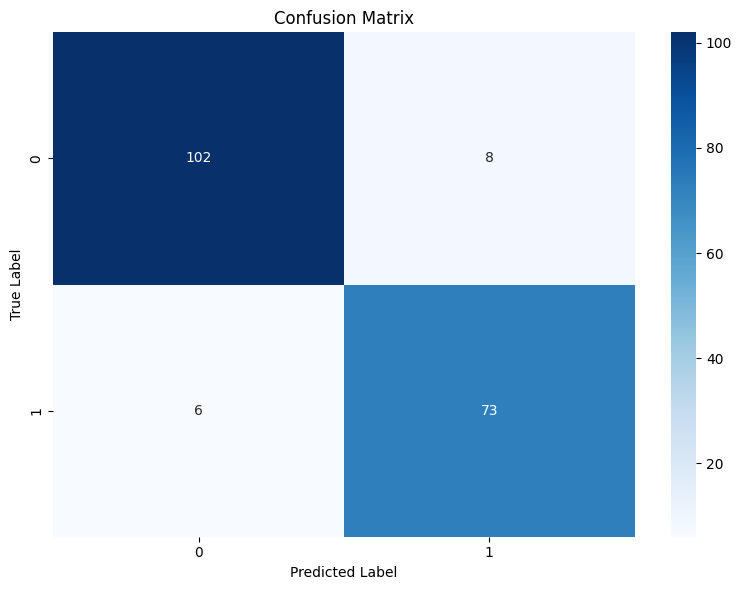

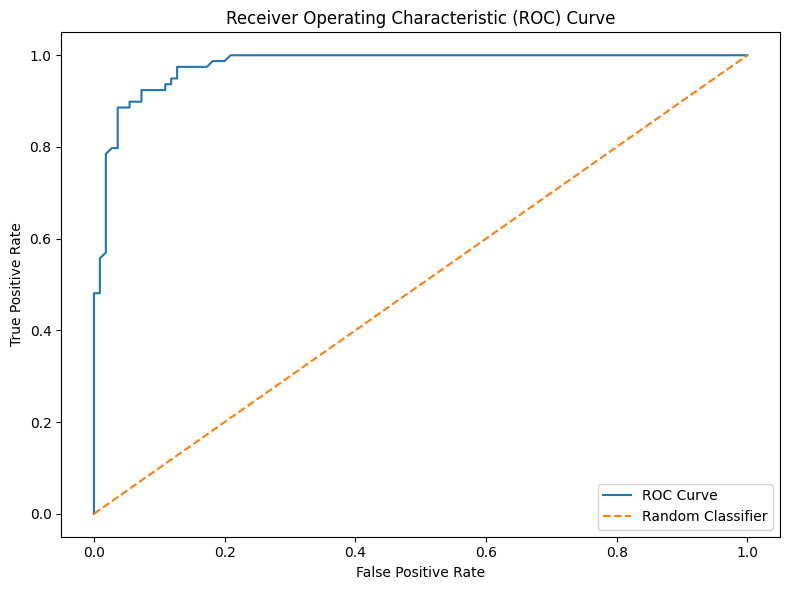

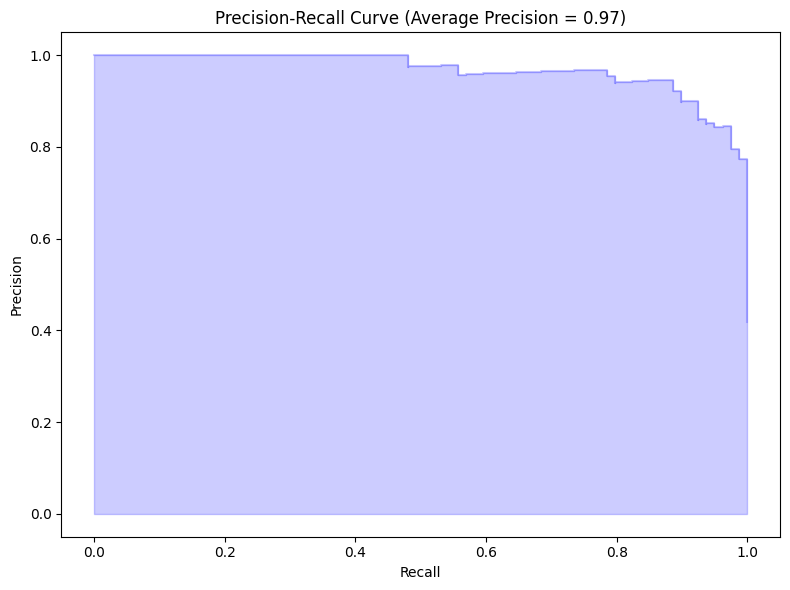

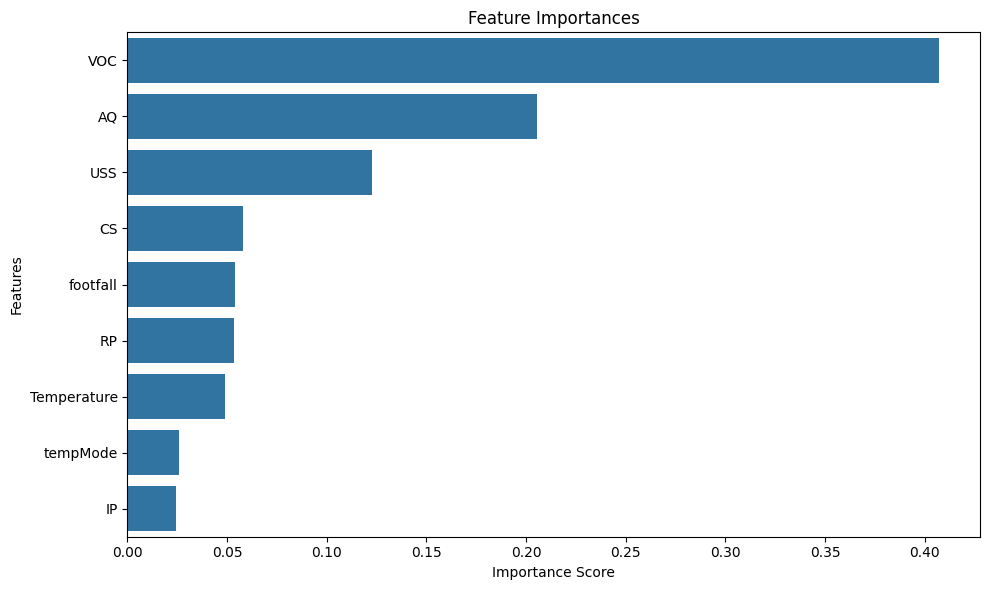

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.93      0.94       110
           1       0.90      0.92      0.91        79

    accuracy                           0.93       189
   macro avg       0.92      0.93      0.92       189
weighted avg       0.93      0.93      0.93       189



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

class PredictiveMaintenanceFirstImplementation:
    def __init__(self, data_path):
        self.df = pd.read_csv(data_path)
        self.X = self.df.drop('fail', axis=1)
        self.y = self.df['fail']

    def preprocess_and_train(self):
        # Split the data
        X_train, X_test, y_train, y_test = train_test_split(
            self.X, self.y, test_size=0.2, random_state=42, stratify=self.y
        )

        # Scale features
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        # Train Random Forest
        rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
        rf_classifier.fit(X_train_scaled, y_train)

        # Predictions
        y_pred = rf_classifier.predict(X_test_scaled)
        y_pred_proba = rf_classifier.predict_proba(X_test_scaled)[:, 1]

        # Evaluation plots
        self.plot_confusion_matrix(y_test, y_pred)
        self.plot_roc_curve(y_test, y_pred_proba)
        self.plot_precision_recall_curve(y_test, y_pred_proba)
        self.plot_feature_importance(rf_classifier)

        # Print metrics
        print("Classification Report:")
        print(classification_report(y_test, y_pred))

        return rf_classifier

    def plot_confusion_matrix(self, y_true, y_pred):
        """
        Plot Confusion Matrix
        """
        plt.figure(figsize=(8, 6))
        cm = confusion_matrix(y_true, y_pred)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
        plt.title('Confusion Matrix')
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.tight_layout()
        plt.show()

    def plot_roc_curve(self, y_true, y_pred_proba):
        """
        Plot ROC Curve
        """
        plt.figure(figsize=(8, 6))
        fpr, tpr, _ = roc_curve(y_true, y_pred_proba)
        plt.plot(fpr, tpr, label='ROC Curve')
        plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
        plt.title('Receiver Operating Characteristic (ROC) Curve')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.legend()
        plt.tight_layout()
        plt.show()

    def plot_precision_recall_curve(self, y_true, y_pred_proba):
        """
        Plot Precision-Recall Curve
        """
        plt.figure(figsize=(8, 6))
        precision, recall, _ = precision_recall_curve(y_true, y_pred_proba)
        avg_precision = average_precision_score(y_true, y_pred_proba)

        plt.step(recall, precision, color='b', alpha=0.2, where='post')
        plt.fill_between(recall, precision, step='post', alpha=0.2, color='b')
        plt.title(f'Precision-Recall Curve (Average Precision = {avg_precision:.2f})')
        plt.xlabel('Recall')
        plt.ylabel('Precision')
        plt.tight_layout()
        plt.show()

    def plot_feature_importance(self, model):
        """
        Plot Feature Importances
        """
        plt.figure(figsize=(10, 6))
        feature_importances = model.feature_importances_
        feature_names = self.X.columns

        # Create importance DataFrame
        importance_df = pd.DataFrame({
            'feature': feature_names,
            'importance': feature_importances
        }).sort_values('importance', ascending=False)

        sns.barplot(x='importance', y='feature', data=importance_df)
        plt.title('Feature Importances')
        plt.xlabel('Importance Score')
        plt.ylabel('Features')
        plt.tight_layout()
        plt.show()

# Usage
if __name__ == '__main__':
    predictor = PredictiveMaintenanceFirstImplementation('/content/Sensor Data.csv')
    model = predictor.preprocess_and_train()

# 2. Second Implementation: Advanced Feature Engineering

### Purpose
Improve model robustness with **SMOTE (oversampling)** and **hyperparameter tuning** using `GridSearchCV`.

---

### Key Enhancements

---

#### ⚖️ Handling Class Imbalance
- Uses **SMOTE** to balance the **minority class**.
- Ensures the classifier doesn't overfit the majority class.

---

#### 🛠️ Hyperparameter Optimization
- Uses **GridSearchCV** to find optimal parameters for `RandomForestClassifier`.
- Optimizes for F1-score (better for imbalanced data).
---
#### 📊  New Visualization

- Class distribution before/after SMOTE.

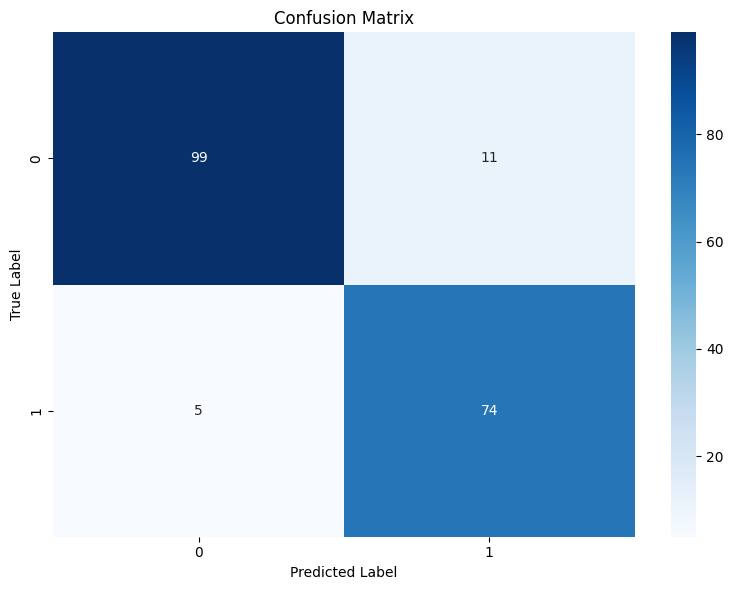

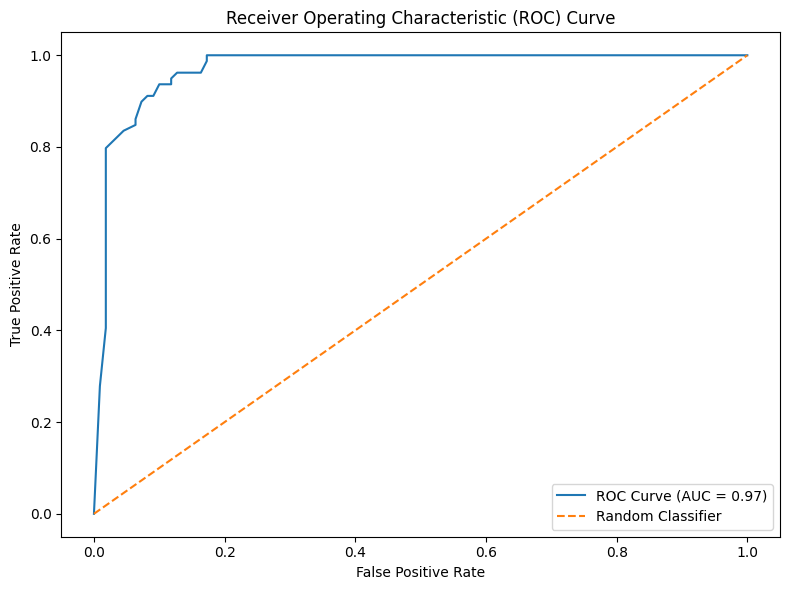

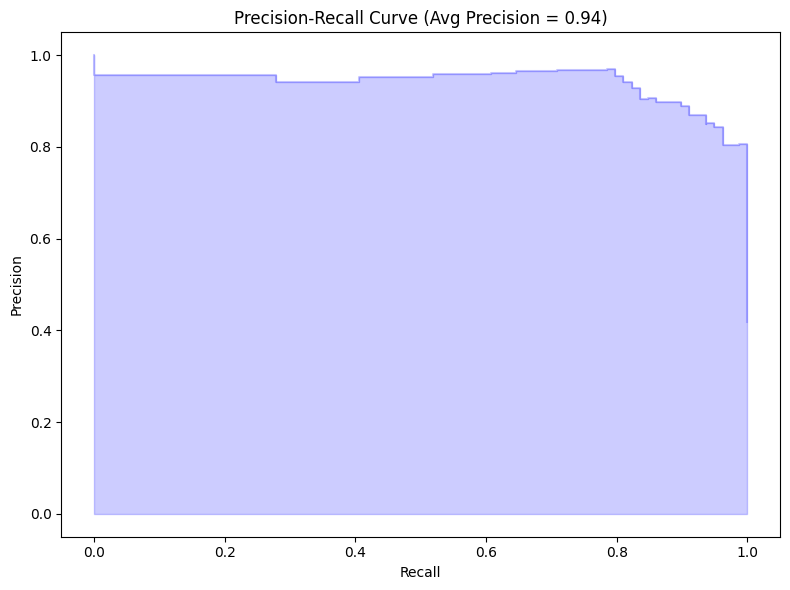

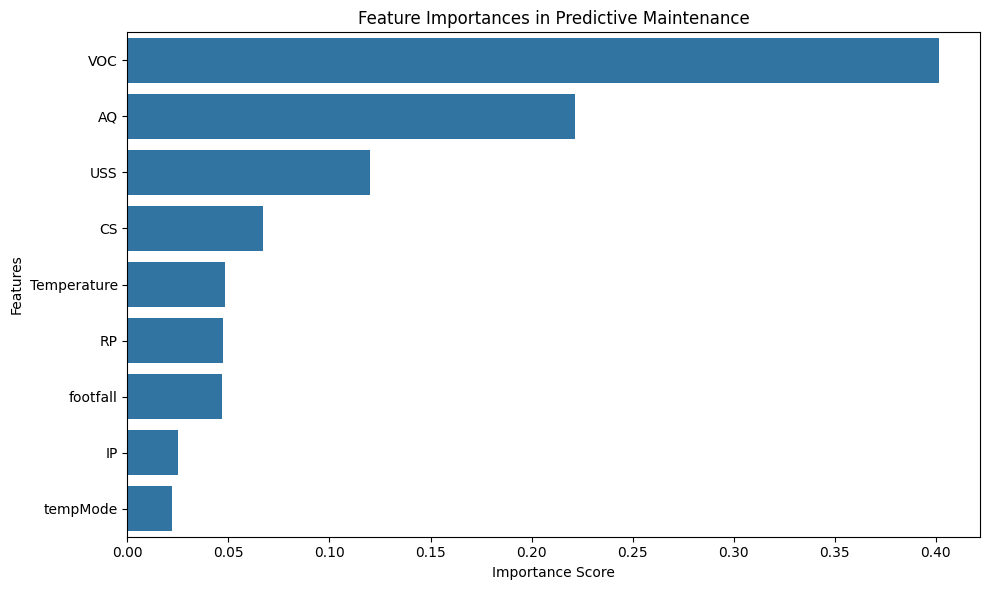

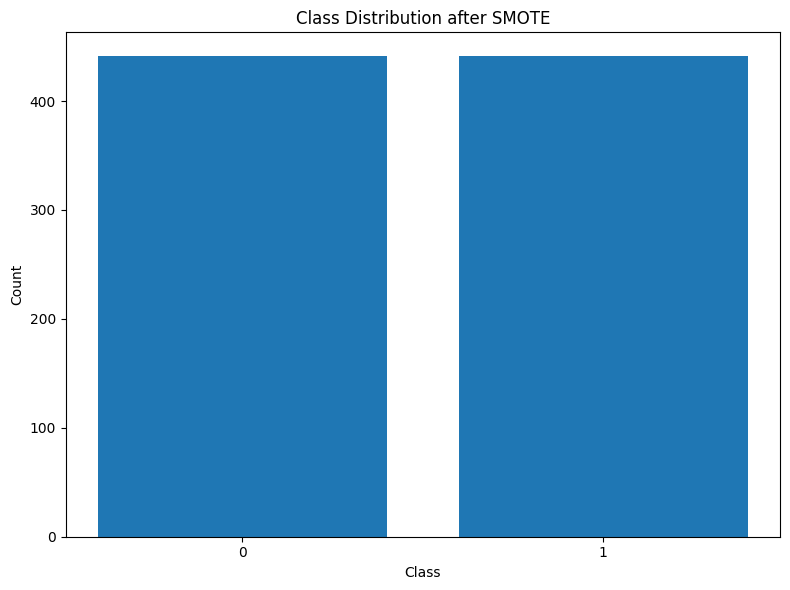

Best Hyperparameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.90      0.93       110
           1       0.87      0.94      0.90        79

    accuracy                           0.92       189
   macro avg       0.91      0.92      0.91       189
weighted avg       0.92      0.92      0.92       189



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)
from imblearn.over_sampling import SMOTE

class PredictiveMaintenanceSecondImplementation:
    def __init__(self, data_path):
        self.df = pd.read_csv(data_path)
        self.X = self.df.drop('fail', axis=1)
        self.y = self.df['fail']

    def comprehensive_model_evaluation(self):
        # Split the data
        X_train, X_test, y_train, y_test = train_test_split(
            self.X, self.y, test_size=0.2, random_state=42, stratify=self.y
        )

        # Apply SMOTE for balancing
        smote = SMOTE(random_state=42)
        X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

        # Scale features
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train_resampled)
        X_test_scaled = scaler.transform(X_test)

        # Define parameter grid
        param_grid = {
            'n_estimators': [50, 100, 200],
            'max_depth': [None, 10, 20],
            'min_samples_split': [2, 5, 10]
        }

        # Grid Search
        rf_classifier = RandomForestClassifier(random_state=42)
        grid_search = GridSearchCV(
            estimator=rf_classifier,
            param_grid=param_grid,
            cv=5,
            scoring='f1'
        )
        grid_search.fit(X_train_scaled, y_train_resampled)

        # Best model
        best_model = grid_search.best_estimator_
        y_pred = best_model.predict(X_test_scaled)
        y_pred_proba = best_model.predict_proba(X_test_scaled)[:, 1]

        # Visualization methods
        self.plot_confusion_matrix(y_test, y_pred)
        self.plot_roc_curve(y_test, y_pred_proba)
        self.plot_precision_recall_curve(y_test, y_pred_proba)
        self.plot_feature_importance(best_model)
        self.plot_class_distribution(y_train_resampled)

        # Classification report
        print("Best Hyperparameters:", grid_search.best_params_)
        print("\nClassification Report:")
        print(classification_report(y_test, y_pred))

        return best_model

    def plot_confusion_matrix(self, y_true, y_pred):
        plt.figure(figsize=(8, 6))
        cm = confusion_matrix(y_true, y_pred)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
        plt.title('Confusion Matrix')
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.tight_layout()
        plt.show()

    def plot_roc_curve(self, y_true, y_pred_proba):
        plt.figure(figsize=(8, 6))
        fpr, tpr, _ = roc_curve(y_true, y_pred_proba)
        auc = roc_auc_score(y_true, y_pred_proba)
        plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc:.2f})')
        plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
        plt.title('Receiver Operating Characteristic (ROC) Curve')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.legend()
        plt.tight_layout()
        plt.show()

    def plot_precision_recall_curve(self, y_true, y_pred_proba):
        plt.figure(figsize=(8, 6))
        precision, recall, _ = precision_recall_curve(y_true, y_pred_proba)
        avg_precision = average_precision_score(y_true, y_pred_proba)

        plt.step(recall, precision, color='b', alpha=0.2, where='post')
        plt.fill_between(recall, precision, step='post', alpha=0.2, color='b')
        plt.title(f'Precision-Recall Curve (Avg Precision = {avg_precision:.2f})')
        plt.xlabel('Recall')
        plt.ylabel('Precision')
        plt.tight_layout()
        plt.show()

    def plot_feature_importance(self, model):
        plt.figure(figsize=(10, 6))
        feature_importances = model.feature_importances_
        feature_names = self.X.columns

        importance_df = pd.DataFrame({
            'feature': feature_names,
            'importance': feature_importances
        }).sort_values('importance', ascending=False)

        sns.barplot(x='importance', y='feature', data=importance_df)
        plt.title('Feature Importances in Predictive Maintenance')
        plt.xlabel('Importance Score')
        plt.ylabel('Features')
        plt.tight_layout()
        plt.show()

    def plot_class_distribution(self, y):
        plt.figure(figsize=(8, 6))
        unique, counts = np.unique(y, return_counts=True)
        plt.bar(unique, counts)
        plt.title('Class Distribution after SMOTE')
        plt.xlabel('Class')
        plt.ylabel('Count')
        plt.xticks(unique)
        plt.tight_layout()
        plt.show()

# Usage
if __name__ == '__main__':
    predictor = PredictiveMaintenanceSecondImplementation('/content/Sensor Data.csv')
    model = predictor.comprehensive_model_evaluation()

# 3. Third Implementation: Comprehensive Visualization

### Purpose
Deepen model interpretability with **advanced Exploratory Data Analysis (EDA)** and **anomaly detection**.

---

### Key Additions

---

#### 📊 New Visualizations

- **Feature distributions** using `sns.histplot`  
  → Understand the spread and skewness of sensor readings.

- **Correlation heatmap** using `sns.heatmap`  
  → Identify multicollinearity and feature relationships.

- **Permutation importance** using `sklearn.inspection.permutation_importance`  
  → Assess feature impact on model accuracy beyond default importance metrics.

- **Anomaly detection** with `IsolationForest`  
  → Detect rare events or unusual patterns that might indicate failure.

---

### ⚙️ Model Improvements

- Uses `class_weight='balanced'` in `RandomForestClassifier`  
  → Automatically adjusts for class imbalance during training without oversampling.

---

✅ This implementation enhances **insight generation** and introduces **early anomaly detection**, making the system more robust and explainable.

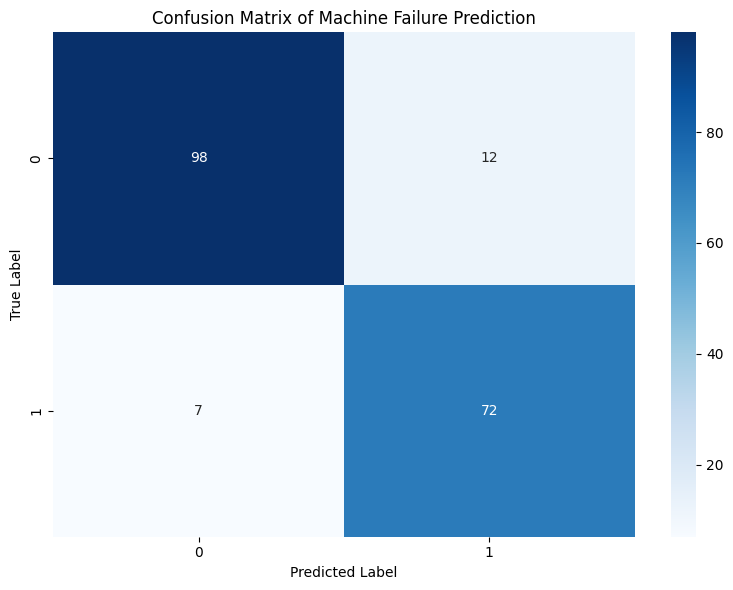

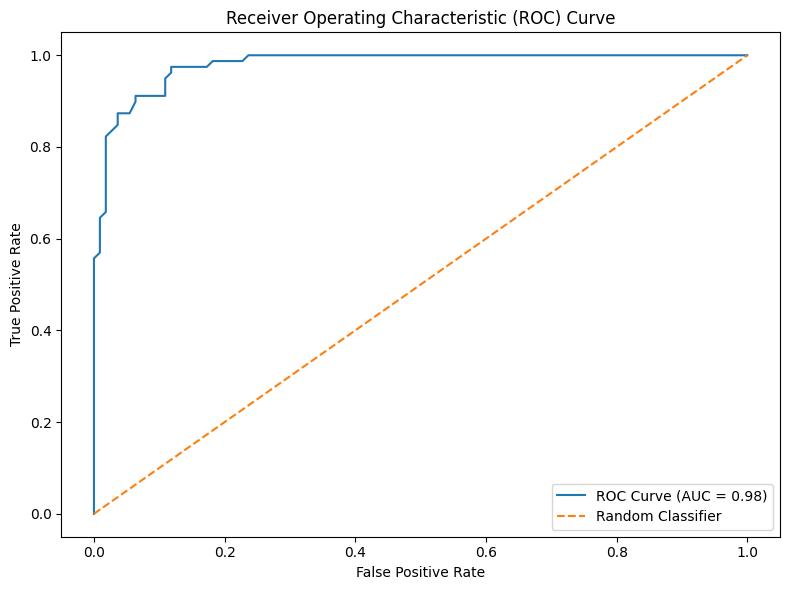

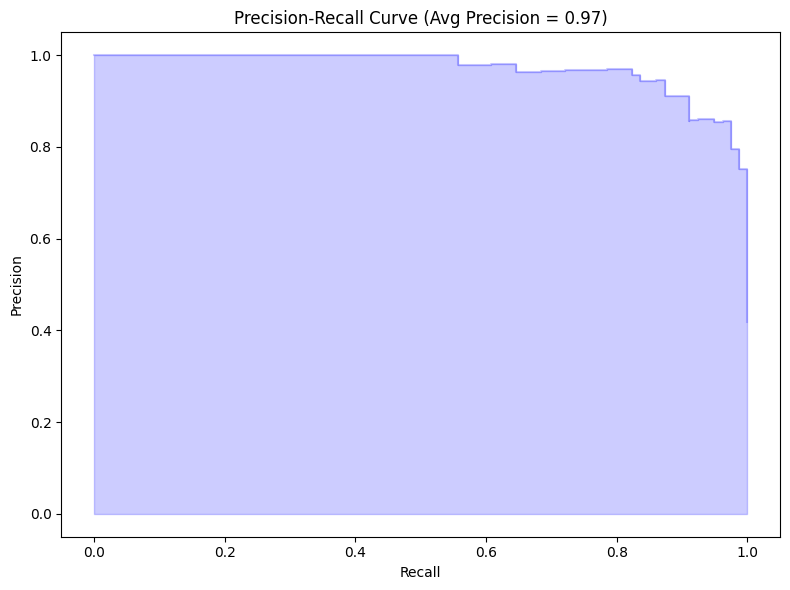

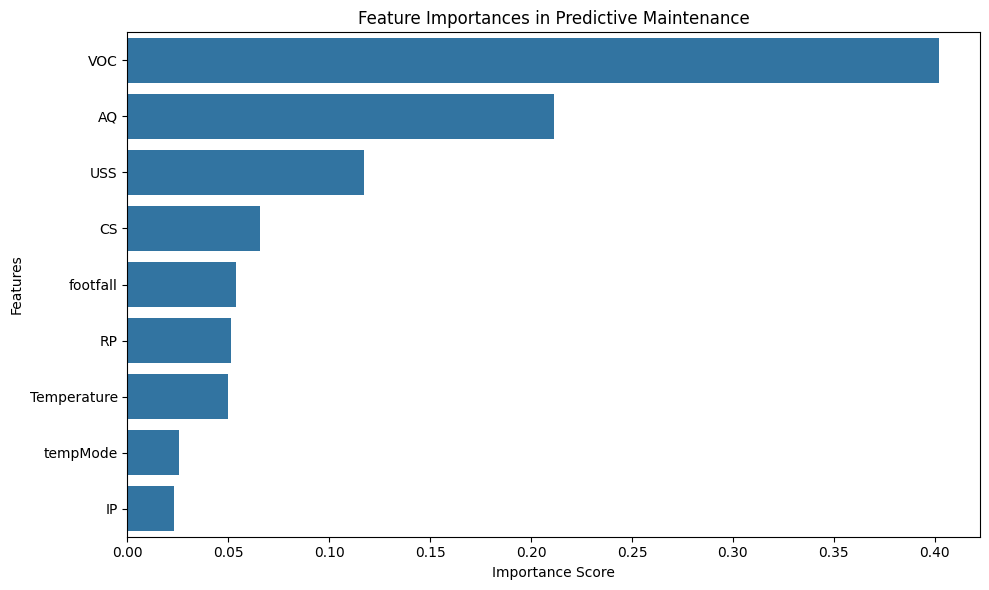

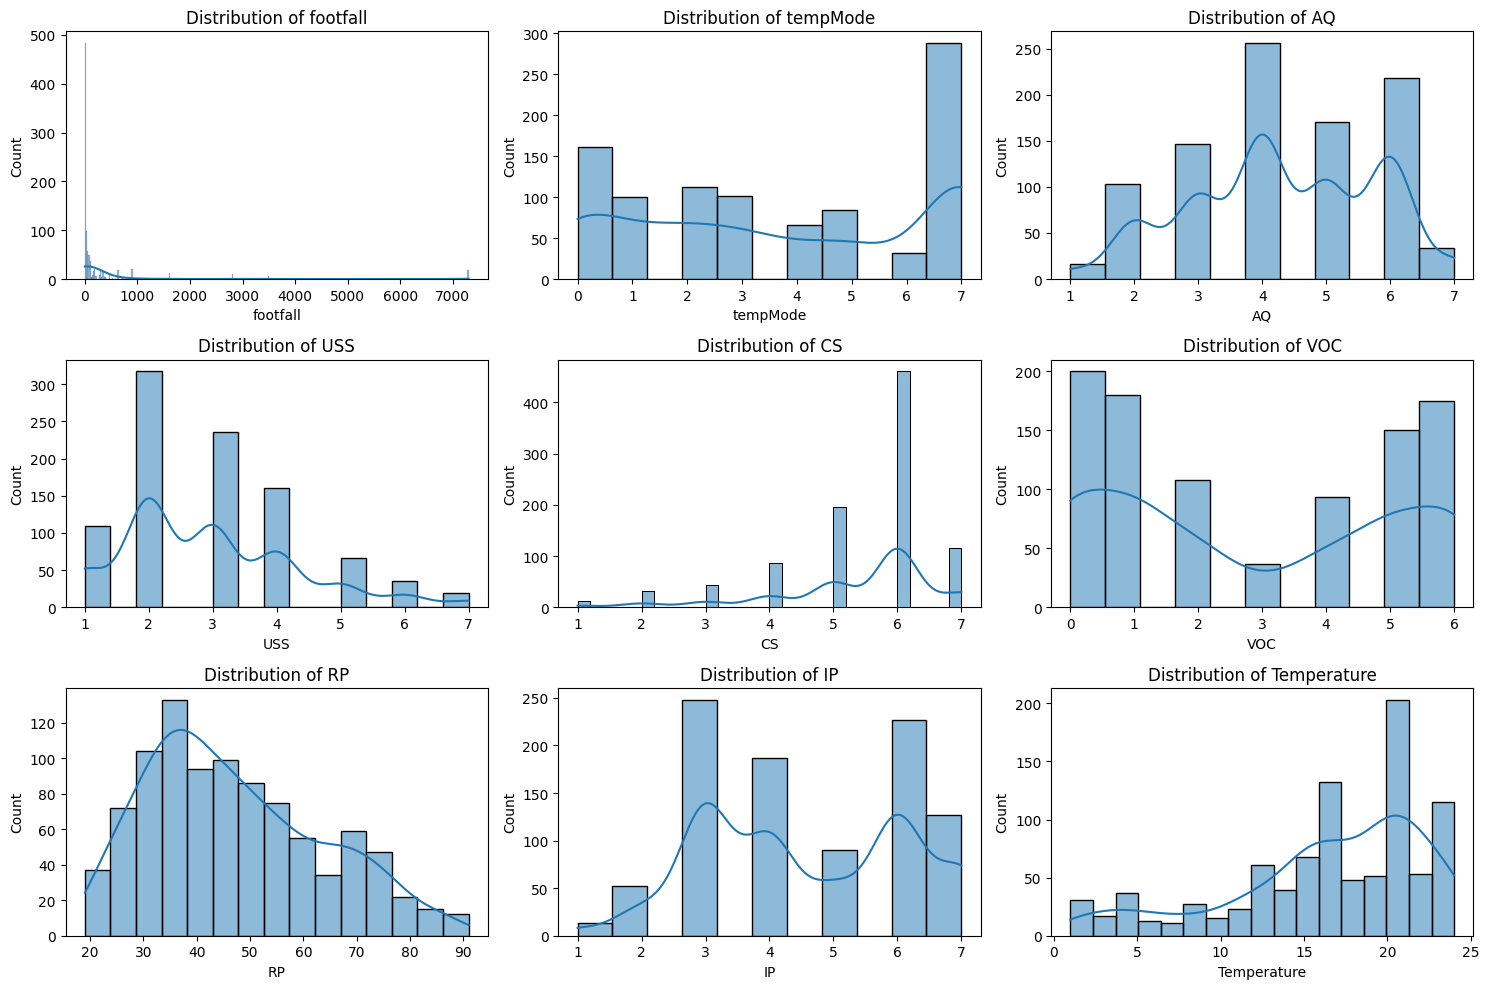

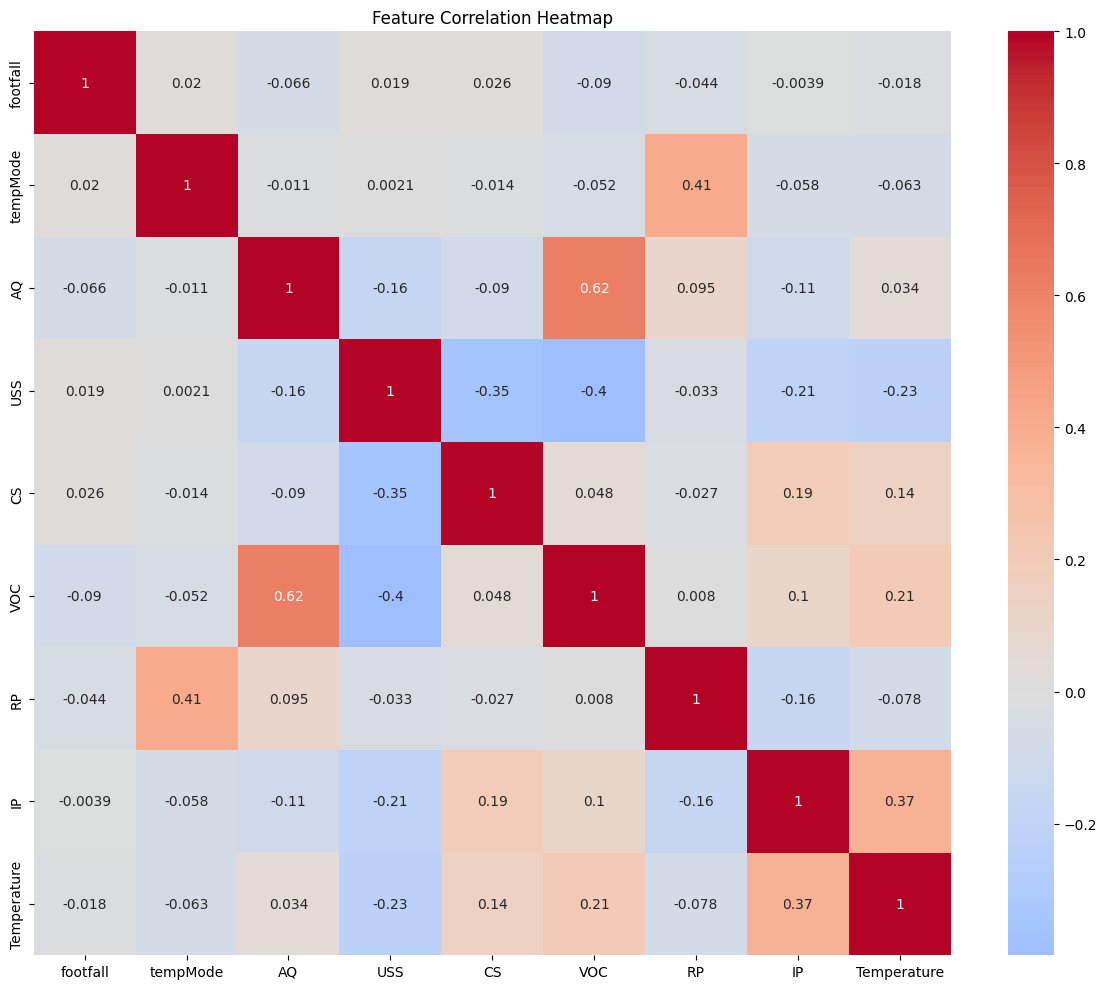

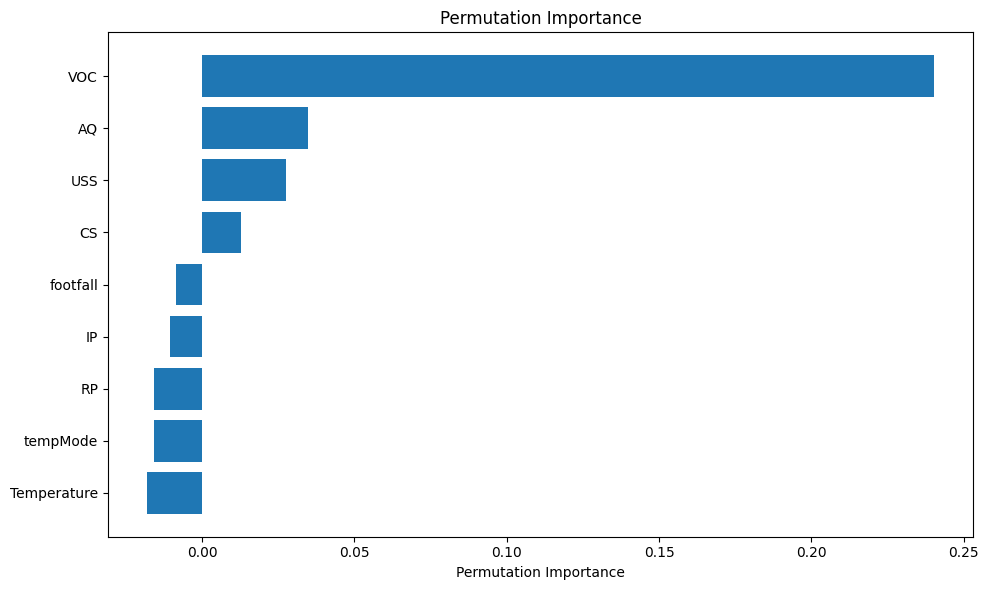

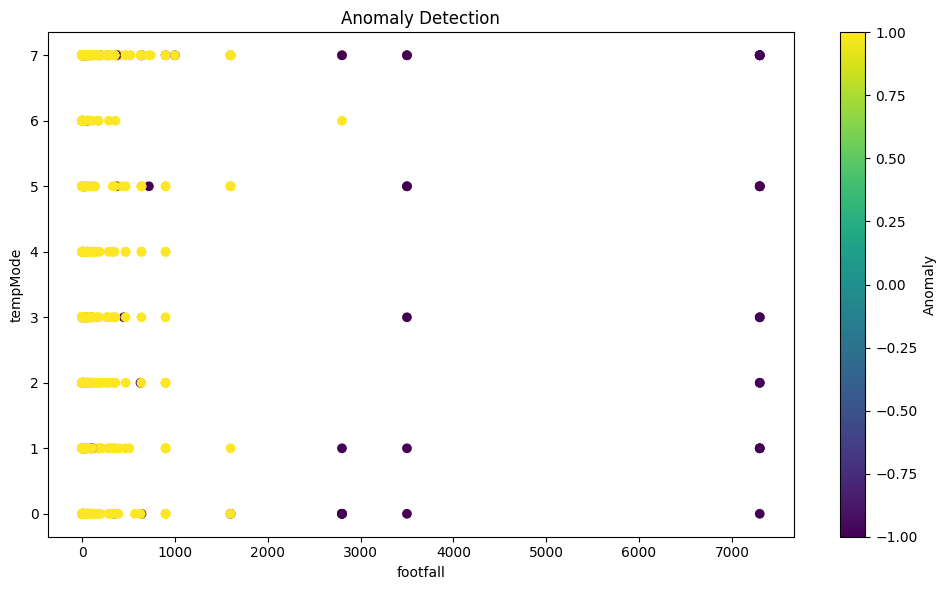


Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.89      0.91       110
           1       0.86      0.91      0.88        79

    accuracy                           0.90       189
   macro avg       0.90      0.90      0.90       189
weighted avg       0.90      0.90      0.90       189



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)
from sklearn.inspection import permutation_importance

class PredictiveMaintenanceSystemWithVisualization:
    def __init__(self, data_path):
        """
        Initialize the Predictive Maintenance System with advanced visualization

        :param data_path: Path to the CSV file
        """
        self.data_path = data_path
        self.load_data()

    def load_data(self):
        """Load and prepare the dataset"""
        self.df = pd.read_csv(self.data_path)

        # Separate features and target
        self.X = self.df.drop('fail', axis=1)
        self.y = self.df['fail']

    def comprehensive_model_evaluation(self):
        """
        Comprehensive model training and evaluation with multiple visualizations
        """
        # Split the data
        X_train, X_test, y_train, y_test = train_test_split(
            self.X, self.y,
            test_size=0.2,
            random_state=42,
            stratify=self.y
        )

        # Scale features
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        # Train Random Forest
        rf_classifier = RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            class_weight='balanced'
        )
        rf_classifier.fit(X_train_scaled, y_train)

        # Predictions
        y_pred = rf_classifier.predict(X_test_scaled)
        y_pred_proba = rf_classifier.predict_proba(X_test_scaled)[:, 1]

        # Visualization methods
        self.plot_confusion_matrix(y_test, y_pred)
        self.plot_roc_curve(y_test, y_pred_proba)
        self.plot_precision_recall_curve(y_test, y_pred_proba)
        self.plot_feature_importance(rf_classifier, X_train)
        self.plot_data_distribution()
        self.plot_correlation_heatmap()
        self.plot_permutation_importance(rf_classifier, X_test_scaled, y_test)

        # Anomaly detection visualization
        self.visualize_anomalies()

        # Print classification report
        print("\nClassification Report:")
        print(classification_report(y_test, y_pred))

        return rf_classifier

    def plot_confusion_matrix(self, y_true, y_pred):
        """
        Plot Confusion Matrix
        """
        plt.figure(figsize=(8, 6))
        cm = confusion_matrix(y_true, y_pred)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
        plt.title('Confusion Matrix of Machine Failure Prediction')
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.tight_layout()
        plt.show()

    def plot_roc_curve(self, y_true, y_pred_proba):
        """
        Plot ROC Curve
        """
        plt.figure(figsize=(8, 6))
        fpr, tpr, _ = roc_curve(y_true, y_pred_proba)
        auc = roc_auc_score(y_true, y_pred_proba)
        plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc:.2f})')
        plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
        plt.title('Receiver Operating Characteristic (ROC) Curve')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.legend()
        plt.tight_layout()
        plt.show()

    def plot_precision_recall_curve(self, y_true, y_pred_proba):
        """
        Plot Precision-Recall Curve
        """
        plt.figure(figsize=(8, 6))
        precision, recall, _ = precision_recall_curve(y_true, y_pred_proba)
        avg_precision = average_precision_score(y_true, y_pred_proba)

        plt.step(recall, precision, color='b', alpha=0.2, where='post')
        plt.fill_between(recall, precision, step='post', alpha=0.2, color='b')
        plt.title(f'Precision-Recall Curve (Avg Precision = {avg_precision:.2f})')
        plt.xlabel('Recall')
        plt.ylabel('Precision')
        plt.tight_layout()
        plt.show()

    def plot_feature_importance(self, model, X_train):
        """
        Plot Feature Importances from Random Forest
        """
        plt.figure(figsize=(10, 6))
        feature_importances = model.feature_importances_
        feature_names = self.X.columns

        importance_df = pd.DataFrame({
            'feature': feature_names,
            'importance': feature_importances
        }).sort_values('importance', ascending=False)

        sns.barplot(x='importance', y='feature', data=importance_df)
        plt.title('Feature Importances in Predictive Maintenance')
        plt.xlabel('Importance Score')
        plt.ylabel('Features')
        plt.tight_layout()
        plt.show()

    def plot_data_distribution(self):
        """
        Plot distribution of numerical features
        """
        plt.figure(figsize=(15, 10))
        for i, col in enumerate(self.X.columns, 1):
            plt.subplot(3, 3, i)
            sns.histplot(self.X[col], kde=True)
            plt.title(f'Distribution of {col}')
        plt.tight_layout()
        plt.show()

    def plot_correlation_heatmap(self):
        """
        Plot correlation heatmap of features
        """
        plt.figure(figsize=(12, 10))
        correlation_matrix = self.X.corr()
        sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
        plt.title('Feature Correlation Heatmap')
        plt.tight_layout()
        plt.show()

    def plot_permutation_importance(self, model, X_test, y_test):
        """
        Plot Permutation Importance
        """
        plt.figure(figsize=(10, 6))
        perm_importance = permutation_importance(model, X_test, y_test)

        feature_names = self.X.columns
        sorted_idx = perm_importance.importances_mean.argsort()

        plt.barh(
            [feature_names[i] for i in sorted_idx],
            perm_importance.importances_mean[sorted_idx]
        )
        plt.title('Permutation Importance')
        plt.xlabel('Permutation Importance')
        plt.tight_layout()
        plt.show()

    def visualize_anomalies(self):
        """
        Visualize anomalies using Isolation Forest
        """
        # Scale features for anomaly detection
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(self.X)

        # Isolation Forest
        isolation_forest = IsolationForest(
            contamination=0.1,
            random_state=42
        )
        anomaly_labels = isolation_forest.fit_predict(X_scaled)

        # Visualization
        plt.figure(figsize=(10, 6))
        plt.scatter(
            self.X.iloc[:, 0],
            self.X.iloc[:, 1],
            c=anomaly_labels,
            cmap='viridis'
        )
        plt.title('Anomaly Detection')
        plt.xlabel(self.X.columns[0])
        plt.ylabel(self.X.columns[1])
        plt.colorbar(label='Anomaly')
        plt.tight_layout()
        plt.show()

# Usage
if __name__ == '__main__':
    predictor = PredictiveMaintenanceSystemWithVisualization('/content/Sensor Data.csv')
    model = predictor.comprehensive_model_evaluation()

# 4. Fourth Implementation: Multiclass Predictive Maintenance

### Purpose
Extend the predictive maintenance system to handle **multiple failure types**, rather than just binary failure classification.

---

### Key Changes

---

#### 🔄 Data Handling

- Renames target column from `fail` → `failure_type`
- Uses **LabelEncoder** to encode **categorical failure types** into numeric labels
- Prepares the dataset for **multiclass classification**

---

#### 🤖 Model Adaptation

- `RandomForestClassifier` is used for **multiclass classification**
  - No structural changes needed — it supports multiclass by default
- Can now distinguish between **different types of failures**

---

#### 📊 Visualizations

- **Failure type distribution** using a **bar plot**
  - Understand class balance across failure categories
- **Multiclass confusion matrix**
  - Uses labeled axes to display true vs predicted failure types clearly

---

✅ This implementation evolves the system into a **more realistic industrial scenario** where different failure modes require different interventions.

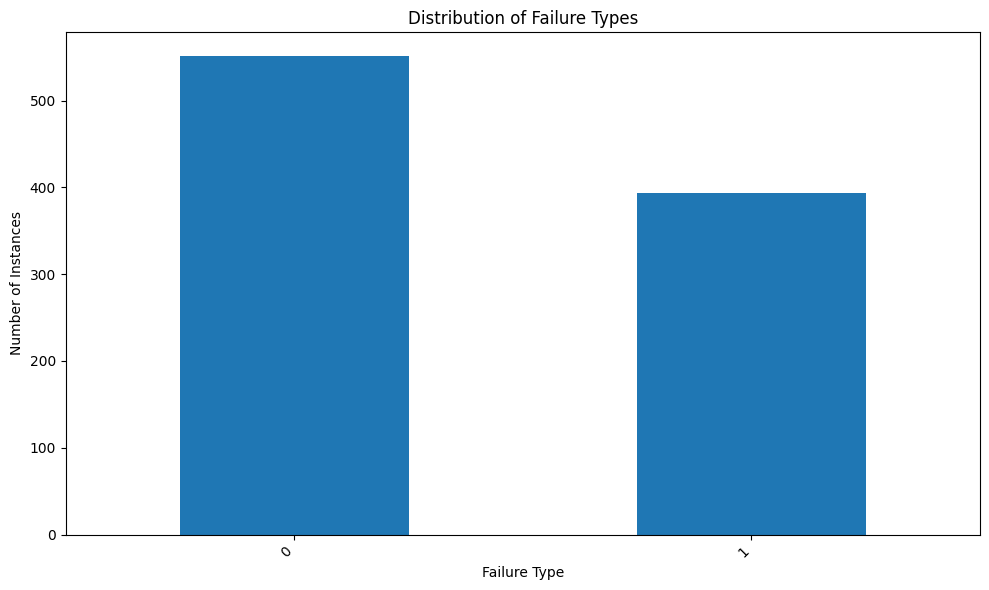

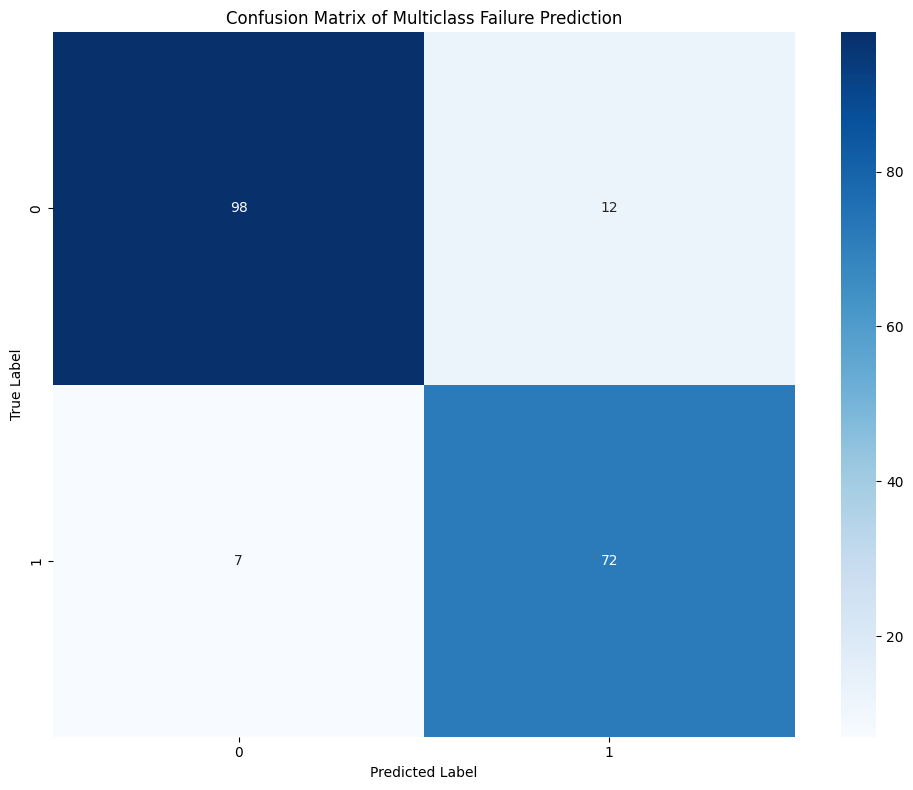

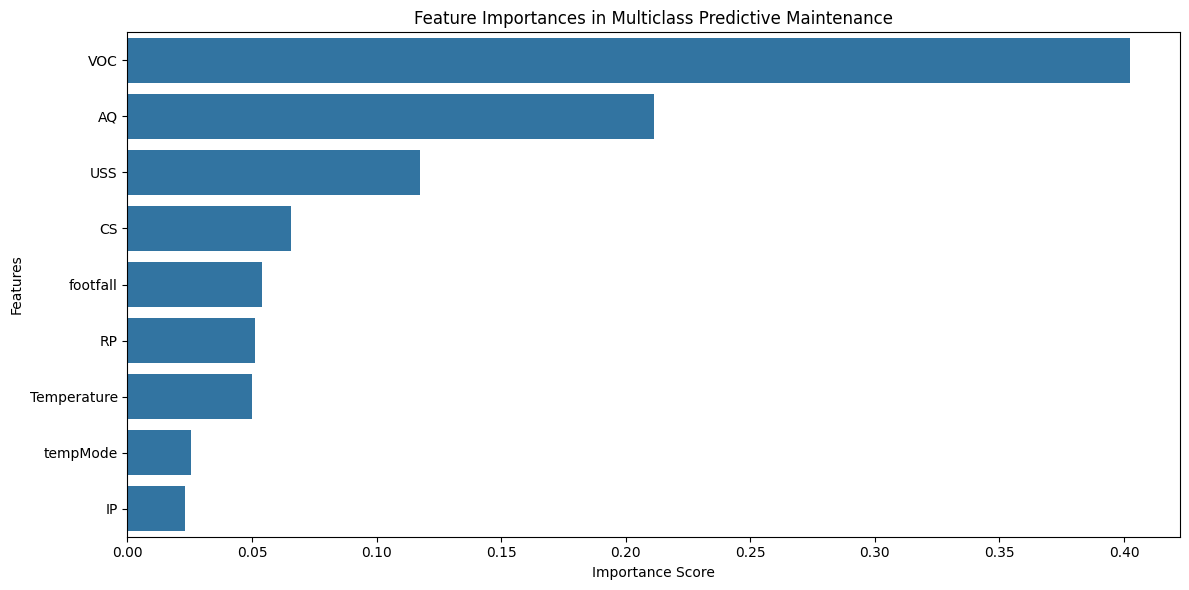


Multiclass Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.89      0.91       110
           1       0.86      0.91      0.88        79

    accuracy                           0.90       189
   macro avg       0.90      0.90      0.90       189
weighted avg       0.90      0.90      0.90       189



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

class MulticlassPredictiveMaintenance:
    def __init__(self, data_path):
        """
        Initialize Multiclass Predictive Maintenance System

        :param data_path: Path to the CSV file with multiclass failure data
        """
        self.data_path = data_path
        self.load_data()

    def load_data(self):
        """
        Load and prepare the multiclass dataset
        """
        self.df = pd.read_csv(self.data_path)

        # Assuming 'fail' column should be used for failure type:
        self.df.rename(columns={"fail": "failure_type"}, inplace=True)

        # Encode failure types
        self.label_encoder = LabelEncoder()
        self.df['failure_type_encoded'] = self.label_encoder.fit_transform(self.df['failure_type'])

        # Separate features and target
        self.X = self.df.drop(['failure_type', 'failure_type_encoded'], axis=1)
        self.y = self.df['failure_type_encoded']

        # Store failure type mapping
        self.failure_type_mapping = dict(zip(
            self.label_encoder.transform(self.label_encoder.classes_),
            self.label_encoder.classes_
        ))

    def train_multiclass_model(self):
        """
        Train a multiclass Random Forest Classifier
        """
        # Split the data
        X_train, X_test, y_train, y_test = train_test_split(
            self.X, self.y,
            test_size=0.2,
            random_state=42,
            stratify=self.y
        )

        # Scale features
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        # Train Random Forest
        rf_classifier = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced',
        # Remove the 'multi_class' parameter
        )
        rf_classifier.fit(X_train_scaled, y_train)

        # Predictions
        y_pred = rf_classifier.predict(X_test_scaled)

        # Visualization and Evaluation
        self.visualize_class_distribution()
        self.plot_confusion_matrix(y_test, y_pred)
        self.plot_feature_importance(rf_classifier, X_train)

        # Classification Report
        print("\nMulticlass Classification Report:")
        # Convert target_names to a list of strings
        target_names = [str(name) for name in self.failure_type_mapping.values()]
        print(classification_report(
            y_test,
            y_pred,
            target_names=target_names
        ))

        return rf_classifier

    def visualize_class_distribution(self):
        """
        Visualize the distribution of failure types
        """
        plt.figure(figsize=(10, 6))
        failure_counts = self.df['failure_type'].value_counts()

        # Create a bar plot of failure type distribution
        failure_counts.plot(kind='bar')
        plt.title('Distribution of Failure Types')
        plt.xlabel('Failure Type')
        plt.ylabel('Number of Instances')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()

    def plot_confusion_matrix(self, y_true, y_pred):
        """
        Plot Confusion Matrix for Multiclass Classification
        """
        plt.figure(figsize=(10, 8))
        cm = confusion_matrix(y_true, y_pred)

        # Use failure type names instead of encoded labels
        failure_types = list(self.failure_type_mapping.values())

        sns.heatmap(
            cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=failure_types,
            yticklabels=failure_types
        )
        plt.title('Confusion Matrix of Multiclass Failure Prediction')
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.tight_layout()
        plt.show()

    def plot_feature_importance(self, model, X_train):
        """
        Plot Feature Importances for Multiclass Model
        """
        plt.figure(figsize=(12, 6))
        feature_importances = model.feature_importances_
        feature_names = self.X.columns

        importance_df = pd.DataFrame({
            'feature': feature_names,
            'importance': feature_importances
        }).sort_values('importance', ascending=False)

        sns.barplot(x='importance', y='feature', data=importance_df)
        plt.title('Feature Importances in Multiclass Predictive Maintenance')
        plt.xlabel('Importance Score')
        plt.ylabel('Features')
        plt.tight_layout()
        plt.show()

# Usage example
if __name__ == '__main__':
    predictor = MulticlassPredictiveMaintenance('/content/Sensor Data.csv')
    model = predictor.train_multiclass_model()

# 5. Fifth Implementation: Advanced Model Comparison

### Purpose
Compare the performance of **Random Forest** and a **Neural Network (Keras)** on predictive maintenance tasks.

---

### Key Additions

---

#### 🤖 Neural Network (Keras)

- Implements a basic **feedforward neural network** using **Keras (TensorFlow backend)**
- Uses `Dense`, `Dropout`, and `ReLU` layers
- Optimizer: `Adam`
- Loss function: `binary_crossentropy` (for binary classification)
- Uses EarlyStopping to prevent overfitting.

---

#### ⚔️ Model Comparison

- **ROC Curve** comparison:
  - Plots ROC for **Random Forest vs. Neural Network**
  - Calculates and displays AUC for both

- **Prediction Probability Histograms**:
  - Visualizes predicted probabilities for both models
  - Helps in understanding how confident each model is in its predictions

---

✅ This implementation highlights **performance trade-offs** between traditional ML and deep learning models in predictive maintenance.


Training Random Forest...
Training Neural Network...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


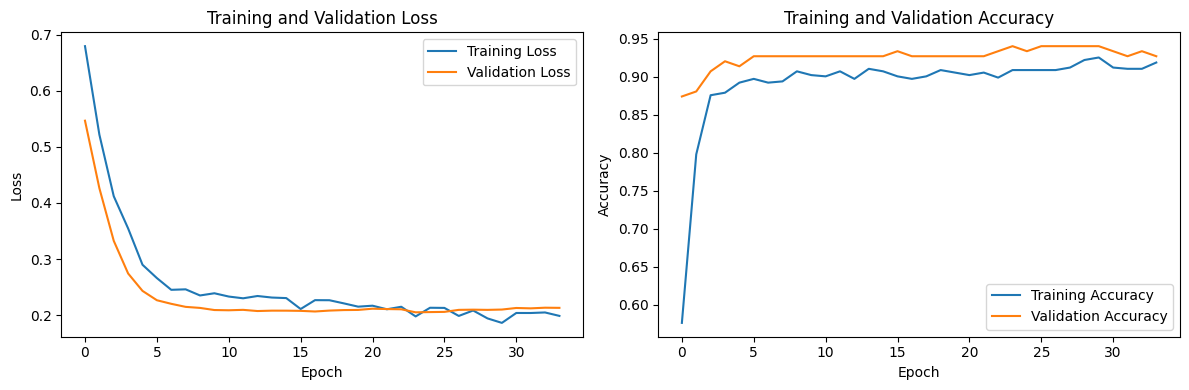

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step

Random Forest Model Evaluation:
              precision    recall  f1-score   support

           0       0.93      0.89      0.91       110
           1       0.86      0.91      0.88        79

    accuracy                           0.90       189
   macro avg       0.90      0.90      0.90       189
weighted avg       0.90      0.90      0.90       189


Neural Network Model Evaluation:
              precision    recall  f1-score   support

           0       0.94      0.94      0.94       110
           1       0.91      0.91      0.91        79

    accuracy                           0.93       189
   macro avg       0.92      0.92      0.92       189
weighted avg       0.93      0.93      0.93       189



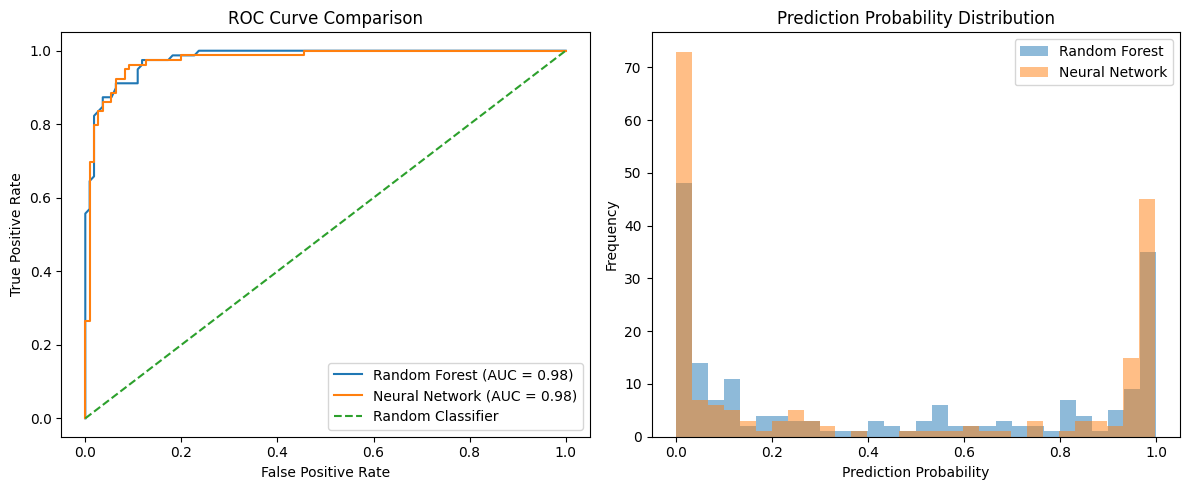

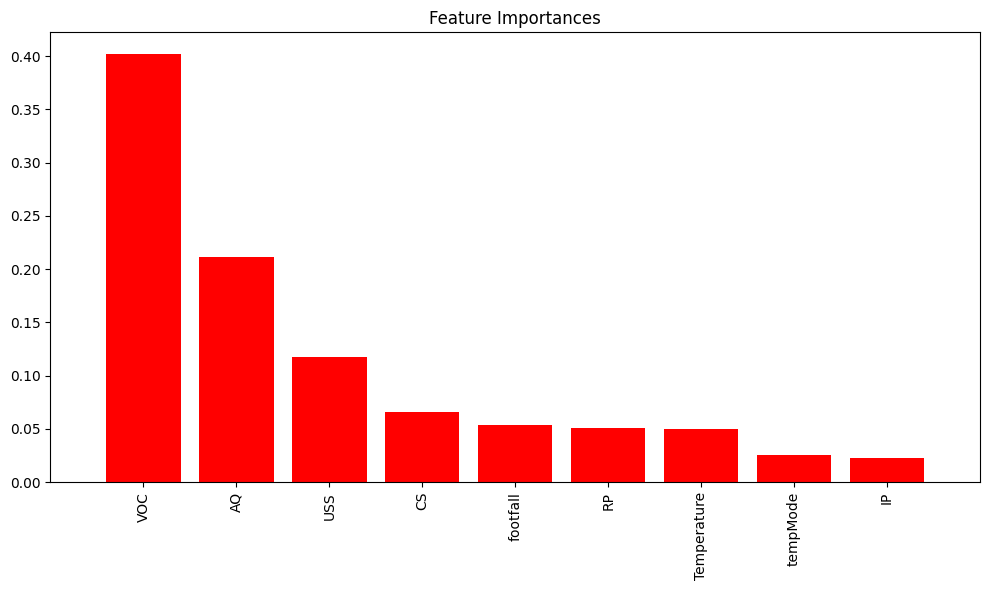

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    accuracy_score
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical

class AdvancedPredictiveMaintenance:
    def __init__(self, data_path, mode='binary'):
        """
        Initialize Advanced Predictive Maintenance System

        :param data_path: Path to the CSV file
        :param mode: 'binary' or 'multiclass'
        """
        self.data_path = data_path
        self.mode = mode
        self.load_data()

    def load_data(self):
        """
        Load and prepare the dataset
        """
        try:
            self.df = pd.read_csv(self.data_path)

            # Check if target column exists
            if 'fail' not in self.df.columns:
                raise ValueError("Target column 'fail' not found in dataset")

            # Separate features and target
            self.X = self.df.drop('fail', axis=1)
            self.y = self.df['fail']

            if self.mode == 'multiclass':
                # Encode labels for multiclass classification
                self.label_encoder = LabelEncoder()
                self.y = self.label_encoder.fit_transform(self.y)

        except Exception as e:
            print(f"Error loading data: {str(e)}")
            raise

    def prepare_data(self):
        """
        Prepare data for model training
        """
        # Split the data
        X_train, X_test, y_train, y_test = train_test_split(
            self.X, self.y,
            test_size=0.2,
            random_state=42,
            stratify=self.y
        )

        # Scale features
        self.scaler = StandardScaler()
        X_train_scaled = self.scaler.fit_transform(X_train)
        X_test_scaled = self.scaler.transform(X_test)

        # For multiclass neural network, convert labels to one-hot encoding
        if self.mode == 'multiclass':
            num_classes = len(np.unique(self.y))
            y_train = to_categorical(y_train, num_classes=num_classes)
            y_test = to_categorical(y_test, num_classes=num_classes)

        return X_train_scaled, X_test_scaled, y_train, y_test

    def train_random_forest(self, X_train, y_train):
        """
        Train Random Forest Classifier
        """
        self.model_rf = RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            class_weight='balanced'
        )
        self.model_rf.fit(X_train, y_train)
        return self.model_rf

    def train_neural_network(self, X_train, y_train):
        """
        Train Neural Network for Predictive Maintenance
        """
        # Determine output layer parameters based on mode
        if self.mode == 'binary':
            output_units = 1
            activation = 'sigmoid'
            loss = 'binary_crossentropy'
        else:
            output_units = y_train.shape[1]
            activation = 'softmax'
            loss = 'categorical_crossentropy'

        # Create Neural Network model
        self.model_nn = Sequential([
            Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
            Dropout(0.3),
            Dense(32, activation='relu'),
            Dropout(0.2),
            Dense(output_units, activation=activation)
        ])

        # Compile the model
        self.model_nn.compile(
            optimizer=Adam(learning_rate=0.001),
            loss=loss,
            metrics=['accuracy']
        )

        # Early stopping to prevent overfitting
        early_stopping = EarlyStopping(
            monitor='val_loss',
            patience=10,
            restore_best_weights=True
        )

        # Train the model
        history = self.model_nn.fit(
            X_train, y_train,
            epochs=100,
            batch_size=32,
            validation_split=0.2,
            callbacks=[early_stopping],
            verbose=0
        )

        return history

    def plot_training_history(self, history):
        """Plot training and validation loss and accuracy"""
        plt.figure(figsize=(12, 4))

        # Plot loss
        plt.subplot(1, 2, 1)
        plt.plot(history.history['loss'], label='Training Loss')
        plt.plot(history.history['val_loss'], label='Validation Loss')
        plt.title('Training and Validation Loss')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.legend()

        # Plot accuracy
        plt.subplot(1, 2, 2)
        plt.plot(history.history['accuracy'], label='Training Accuracy')
        plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
        plt.title('Training and Validation Accuracy')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.legend()

        plt.tight_layout()
        plt.show()

    def evaluate_models(self):
        """
        Comprehensive model evaluation
        """
        # Prepare data
        X_train, X_test, y_train, y_test = self.prepare_data()

        # Train models
        print("Training Random Forest...")
        rf_model = self.train_random_forest(X_train, y_train)

        print("Training Neural Network...")
        nn_history = self.train_neural_network(X_train, y_train)
        self.plot_training_history(nn_history)

        # RF Predictions
        rf_pred = rf_model.predict(X_test)
        rf_pred_proba = rf_model.predict_proba(X_test)[:, 1] if self.mode == 'binary' else rf_model.predict_proba(X_test)

        # NN Predictions
        nn_pred_proba = self.model_nn.predict(X_test)
        if self.mode == 'binary':
            nn_pred = (nn_pred_proba > 0.5).astype(int)
        else:
            nn_pred = np.argmax(nn_pred_proba, axis=1)
            y_test_labels = np.argmax(y_test, axis=1) if self.mode == 'multiclass' else y_test

        # Evaluate Random Forest
        print("\nRandom Forest Model Evaluation:")
        print(classification_report(y_test_labels if self.mode == 'multiclass' else y_test,
                                  rf_pred))

        # Evaluate Neural Network
        print("\nNeural Network Model Evaluation:")
        print(classification_report(y_test_labels if self.mode == 'multiclass' else y_test,
                                  nn_pred))

        # Visualizations
        if self.mode == 'binary':
            self.plot_model_comparison(y_test, rf_pred_proba, nn_pred_proba)

        return rf_model, self.model_nn

    def plot_model_comparison(self, y_true, rf_pred_proba, nn_pred_proba):
        """
        Visualize model performance comparison
        """
        plt.figure(figsize=(12, 5))

        # ROC AUC Scores
        rf_auc = roc_auc_score(y_true, rf_pred_proba)
        nn_auc = roc_auc_score(y_true, nn_pred_proba)

        # Subplot 1: ROC Curves
        plt.subplot(1, 2, 1)
        rf_fpr, rf_tpr, _ = roc_curve(y_true, rf_pred_proba)
        plt.plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {rf_auc:.2f})')

        nn_fpr, nn_tpr, _ = roc_curve(y_true, nn_pred_proba)
        plt.plot(nn_fpr, nn_tpr, label=f'Neural Network (AUC = {nn_auc:.2f})')

        plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
        plt.title('ROC Curve Comparison')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.legend()

        # Subplot 2: Prediction Probabilities Distribution
        plt.subplot(1, 2, 2)
        plt.hist(rf_pred_proba, bins=30, alpha=0.5, label='Random Forest')
        plt.hist(nn_pred_proba, bins=30, alpha=0.5, label='Neural Network')
        plt.title('Prediction Probability Distribution')
        plt.xlabel('Prediction Probability')
        plt.ylabel('Frequency')
        plt.legend()

        plt.tight_layout()
        plt.show()

    def plot_feature_importance(self):
        """Plot feature importance for Random Forest model"""
        if hasattr(self, 'model_rf'):
            importances = self.model_rf.feature_importances_
            indices = np.argsort(importances)[::-1]

            plt.figure(figsize=(10, 6))
            plt.title("Feature Importances")
            plt.bar(range(self.X.shape[1]), importances[indices],
                   color="r", align="center")
            plt.xticks(range(self.X.shape[1]), self.X.columns[indices], rotation=90)
            plt.xlim([-1, self.X.shape[1]])
            plt.tight_layout()
            plt.show()

# Usage example
if __name__ == '__main__':
    try:
        predictor = AdvancedPredictiveMaintenance('/content/Sensor Data.csv', mode='binary')
        rf_model, nn_model = predictor.evaluate_models()
        predictor.plot_feature_importance()
    except Exception as e:
        print(f"Error in predictive maintenance system: {str(e)}")

# 6. Sixth Implementation: Fuzzy C-Means Clustering

### Purpose
Integrate **unsupervised learning** using **Fuzzy C-Means** for enhanced anomaly detection and interpretability.

---

### Key Features

---

#### 🧠 Custom Fuzzy C-Means

- Implements **soft clustering** (membership probabilities) instead of hard labels
- Parameters:
  - `n_clusters = 3`
  - `m = 2` (fuzziness coefficient)
- Outputs a **membership matrix**, indicating how strongly each data point belongs to each cluster

---

#### 🔍 User Input Prediction

- Accepts **real-time sensor inputs** from users
- Combines predictions from:
  - **Random Forest (RF)**
  - **Neural Network (NN)**
- Helps make decisions based on consensus or confidence levels

---

#### 📊 Visualizations

- **Prediction probabilities** displayed using a **bar chart**
  - Shows how RF and NN evaluate the input
- **Cluster centers** visualized using a **scatter plot**
  - Displays the learned cluster structure in 2D/3D space

---

✅ This hybrid implementation combines **unsupervised learning** with **real-time prediction**, improving both **anomaly detection** and **model transparency**.

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


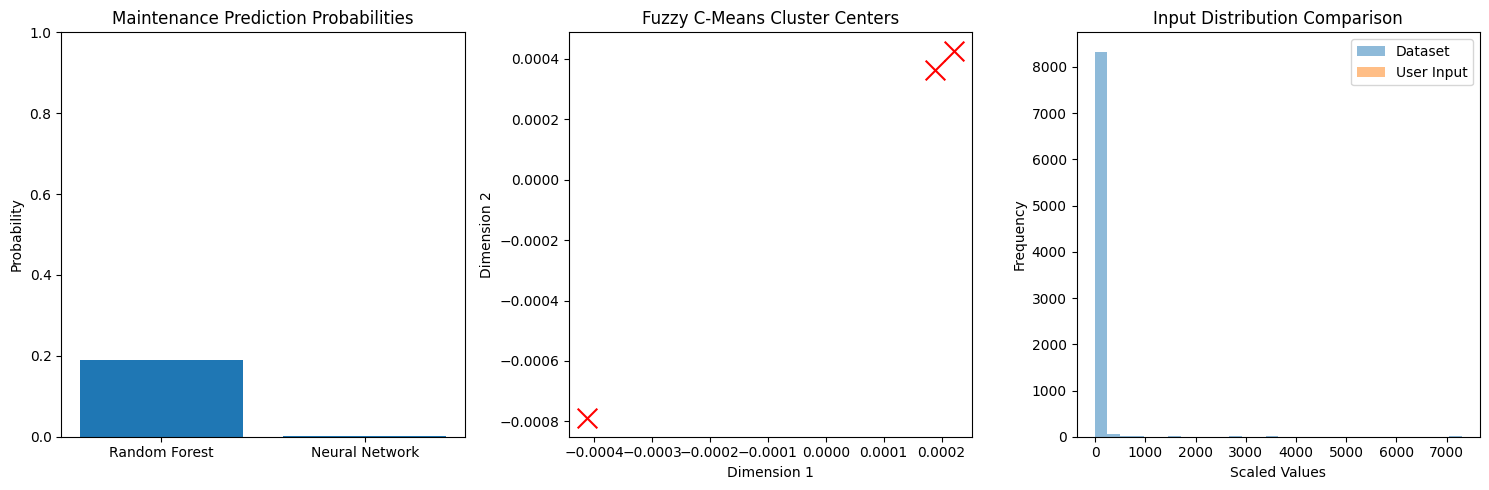


Maintenance Prediction Results:
Random Forest Probability: 0.19
Neural Network Probability: 0.001468118280172348
Combined Maintenance Probability: 0.09573405914008618
Maintenance Needed: False


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
#from tensorflow.keras.callbacks import EarlyStopping # EarlyStopping is not used in this implementation
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist

# Fuzzy C-Means Implementation
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import cdist

class FuzzyCMeans:
    def __init__(self, n_clusters=3, m=2, max_iter=100, error=1e-5):
        """
        Fuzzy C-Means Clustering Algorithm

        :param n_clusters: Number of clusters
        :param m: Fuzzy coefficient (typically 2)
        :param max_iter: Maximum iterations
        :param error: Convergence threshold
        """
        self.n_clusters = n_clusters
        self.m = m
        self.max_iter = max_iter
        self.error = error
        self.centers = None
        self.u = None

    def fit(self, X):
        """
        Perform Fuzzy C-Means Clustering

        :param X: Input data
        :return: Cluster centers and membership matrix
        """
        # Normalize data
        X = (X - X.mean(axis=0)) / X.std(axis=0)

        # Initialize membership matrix randomly
        n_samples, n_features = X.shape
        self.u = np.random.dirichlet(np.ones(self.n_clusters), size=n_samples)
        self.u = self.u / self.u.sum(axis=1)[:, np.newaxis]

        for _ in range(self.max_iter):
            # Store previous centers
            old_centers = self.centers.copy() if self.centers is not None else None

            # Update cluster centers
            self.centers = self._update_centers(X)

            # Update membership matrix
            new_u = self._update_membership(X)

            # Check convergence
            if old_centers is not None and np.linalg.norm(self.centers - old_centers) < self.error:
                break

            self.u = new_u

        return self.centers, self.u

    def _update_centers(self, X):
        """
        Update cluster centers

        :param X: Input data
        :return: Updated cluster centers
        """
        um = self.u ** self.m
        centers = (um.T @ X) / um.sum(axis=0)[:, np.newaxis]
        return centers

    def _update_membership(self, X):
        """
        Update membership matrix

        :param X: Input data
        :return: Updated membership matrix
        """
        # Calculate distances
        distances = cdist(X, self.centers)

        # Prevent division by zero
        distances = np.maximum(distances, 1e-10)

        # Calculate membership
        membership = 1 / (distances ** (2 / (self.m - 1)) *
                          np.sum((1 / distances) ** (2 / (self.m - 1)), axis=1)[:, np.newaxis])

        return membership

class ComprehensivePredictiveMaintenance:
    def __init__(self, data_path):
        """
        Comprehensive Predictive Maintenance System

        :param data_path: Path to the CSV file
        """
        self.data_path = data_path
        self.load_data()

    def load_data(self):
        """
        Load and prepare the dataset
        """
        self.df = pd.read_csv(self.data_path)

        # Separate features and target
        self.X = self.df.drop('fail', axis=1)
        self.y = self.df['fail']

    def preprocess_data(self):
        """
        Preprocess data for multiple models
        """
        # Scale features
        self.scaler = StandardScaler()
        X_scaled = self.scaler.fit_transform(self.X)

        # Split the data
        X_train, X_test, y_train, y_test = train_test_split(
            X_scaled, self.y,
            test_size=0.2,
            random_state=42,
            stratify=self.y
        )

        return X_train, X_test, y_train, y_test

    def train_models(self, X_train, y_train):
        """
        Train multiple models
        """
        # Random Forest
        rf_model = RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            class_weight='balanced'
        )
        rf_model.fit(X_train, y_train)

        # Neural Network
        nn_model = self._create_neural_network(X_train.shape[1])
        nn_model.fit(
            X_train, y_train,
            epochs=100,
            batch_size=32,
            validation_split=0.2,
            verbose=0
        )

        return rf_model, nn_model

    def _create_neural_network(self, input_shape):
        """
        Create Neural Network model
        """
        model = Sequential([
            Dense(64, activation='relu', input_shape=(input_shape,)),
            Dropout(0.3),
            Dense(32, activation='relu'),
            Dropout(0.2),
            Dense(1, activation='sigmoid')
        ])

        model.compile(
            optimizer=Adam(learning_rate=0.001),
            loss='binary_crossentropy',
            metrics=['accuracy']
        )

        return model

    def predict_maintenance(self, user_input):
        """
        Predict maintenance need based on user input

        :param user_input: Dictionary of sensor measurements
        :return: Maintenance prediction and visualization
        """
        # Call preprocess_data to initialize self.scaler
        self.preprocess_data()

        # Prepare user input
        # Ensure user_input has the same column names as self.X
        input_df = pd.DataFrame([user_input], columns=self.X.columns)

        # Fill NaN values with 0 before scaling (or use another appropriate strategy)
        input_df.fillna(0, inplace=True)  # Replace NaN with 0

        # Scale input using the same scaler
        input_scaled = self.scaler.transform(input_df)

        # Predict using both models
        X_train, X_test, y_train, y_test = self.preprocess_data()
        rf_model, nn_model = self.train_models(X_train, y_train)

        # Predictions
        rf_pred_proba = rf_model.predict_proba(input_scaled)[0, 1]
        nn_pred_proba = nn_model.predict(input_scaled)[0, 0]

        # Fuzzy C-Means Clustering
        fcm = FuzzyCMeans(n_clusters=3)
        fcm.fit(X_train)

        # Visualize results
        self._visualize_predictions(rf_pred_proba, nn_pred_proba, fcm, input_scaled)

        # Combine predictions
        combined_pred = (rf_pred_proba + nn_pred_proba) / 2

        return {
            'Random Forest Probability': rf_pred_proba,
            'Neural Network Probability': nn_pred_proba,
            'Combined Maintenance Probability': combined_pred,
            'Maintenance Needed': combined_pred > 0.7
        }

    def _visualize_predictions(self, rf_pred, nn_pred, fcm, input_scaled):
        """
        Visualize prediction results and clustering
        """
        plt.figure(figsize=(15, 5))

        # Subplot 1: Prediction Probabilities
        plt.subplot(1, 3, 1)
        predictions = [rf_pred, nn_pred]
        models = ['Random Forest', 'Neural Network']
        plt.bar(models, predictions)
        plt.title('Maintenance Prediction Probabilities')
        plt.ylabel('Probability')
        plt.ylim(0, 1)

        # Subplot 2: Fuzzy Clustering Visualization
        plt.subplot(1, 3, 2)
        # Project data to 2D for visualization (using first two features)
        plt.scatter(
            fcm.centers[:, 0],
            fcm.centers[:, 1],
            c='red',
            marker='x',
            s=200,
            label='Cluster Centers'
        )
        plt.title('Fuzzy C-Means Cluster Centers')
        plt.xlabel('Dimension 1')
        plt.ylabel('Dimension 2')

        # Subplot 3: User Input vs Dataset
        plt.subplot(1, 3, 3)
        plt.hist(self.X.values.flatten(), bins=30, alpha=0.5, label='Dataset')
        plt.hist(input_scaled.flatten(), bins=10, alpha=0.5, label='User Input')
        plt.title('Input Distribution Comparison')
        plt.xlabel('Scaled Values')
        plt.ylabel('Frequency')
        plt.legend()

        plt.tight_layout()
        plt.show()

# Usage Example
if __name__ == '__main__':
    # Initialize the system
    predictor = ComprehensivePredictiveMaintenance('/content/Sensor Data.csv')

    # Example user input (modify according to your dataset features)
    user_input = {
        'temperature': 7,
        'vibration': 7,
        'pressure': 100,
        'noise_level': 60,
        # Add other relevant features
    }

    # Predict maintenance need
    result = predictor.predict_maintenance(user_input)

    # Print results
    print("\nMaintenance Prediction Results:")
    for key, value in result.items():
        print(f"{key}: {value}")

# 7. Seventh Implementation: Advanced Fuzzy C-Means

### Purpose
Enhance Fuzzy C-Means clustering with **kernel methods**, **regularization**, and **entropy-based analysis** for deeper insights and stability.

---

### Key Improvements

---

#### 🧠 Advanced FCM

- Supports **kernelized FCM**:
  - Kernel options: `gaussian`, `polynomial`
  - Enables non-linear cluster boundaries for complex data
- Adds a **regularization term** (`λ = 1e-4`) to the objective function
  - Improves **numerical stability** and prevents overfitting
- Computes **cluster entropy** to quantify **uncertainty in membership**
  - Useful for detecting overlapping or ambiguous clusters

---

#### 📊 Enhanced Visualizations

- **Cluster evolution** over iterations
  - Tracks how cluster centers move during training
- **Membership matrix heatmap**
  - Shows the degree of belonging for each data point across all clusters

---

✅ This version introduces **mathematically rigorous improvements** to clustering, leading to **more flexible, stable, and interpretable** anomaly detection.


--- Predictive Maintenance System ---
Enter sensor measurements:
Enter footfall value (min(1),max(730)): 600
Enter tempMode value (min(0),max(7)): 5
Enter AQ value (min(0),max(7)): 4
Enter USS value (min(0),max(7)): 7
Enter CS value (min(0),max(7)): 3
Enter VOC value (min(0),max(6)): 5
Enter RP value (min(19),max(91)): 40
Enter IP value (min(1),max(7)): 5
Enter Temperature value (min(1)),max(24)): 20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 427ms/step


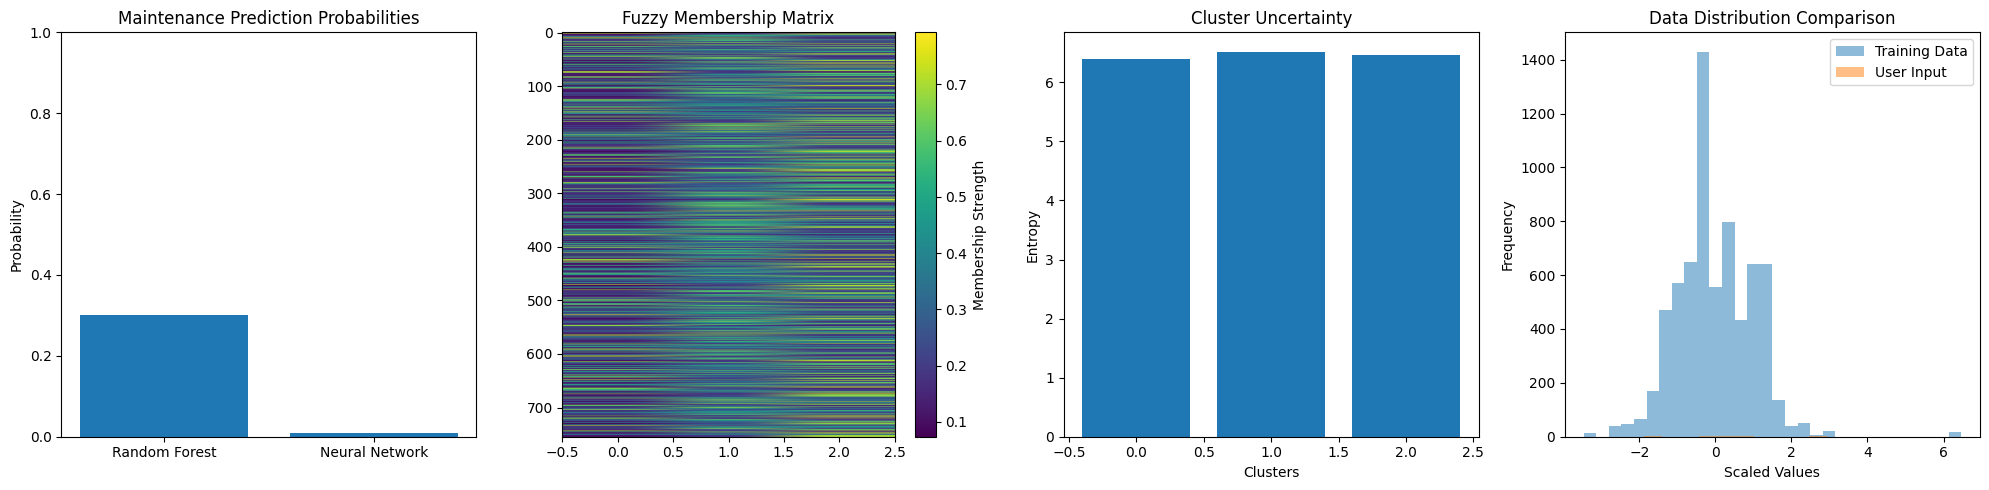


--- Maintenance Prediction Results ---
Random Forest Probability: 0.3
Neural Network Probability: 0.008975328877568245
Combined Maintenance Probability: 0.15448766443878412
Maintenance Needed: False
Cluster Entropies: [np.float64(6.398445508701237), np.float64(6.51974474367085), np.float64(6.468191869367184)]
Silhouette Score: 0.25738400526992916


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Model
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.stats import entropy

class AdvancedFuzzyCMeans:
    def __init__(self,
                 n_clusters=3,
                 m=2,
                 max_iter=200,
                 error=1e-6,
                 kernel_type='gaussian',
                 regularization=1e-4):
        """
        Advanced Fuzzy C-Means Clustering with Enhanced Features
        """
        self.n_clusters = n_clusters
        self.m = m
        self.max_iter = max_iter
        self.error = error
        self.kernel_type = kernel_type
        self.regularization = regularization

        self.centers = None
        self.u = None
        self.cluster_entropies = None
        self.silhouette_scores = None

    def _kernel_function(self, X):
        """
        Apply kernel transformation for non-linear clustering
        """
        if self.kernel_type == 'gaussian':
            gamma = 1.0 / (2 * X.shape[1])
            pairwise_dists = cdist(X, X, 'euclidean')
            return np.exp(-gamma * (pairwise_dists ** 2))
        elif self.kernel_type == 'polynomial':
            return (1 + X @ X.T) ** 3
        else:
            return X

    def fit(self, X):
        """
        Perform Advanced Fuzzy C-Means Clustering
        """
        # Preprocessing
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)

        # Apply PCA for dimensionality reduction and noise reduction
        pca = PCA(n_components=min(X.shape[1], 10))
        X_pca = pca.fit_transform(X_scaled)

        # Apply kernel transformation
        X_kernel = self._kernel_function(X_pca)

        # Initialize membership matrix
        n_samples, n_features = X_kernel.shape
        self.u = np.random.dirichlet(np.ones(self.n_clusters), size=n_samples)
        self.u = self.u / self.u.sum(axis=1)[:, np.newaxis]

        # Tracking variables
        cluster_histories = []

        for iteration in range(self.max_iter):
            # Store previous centers
            old_centers = self.centers.copy() if self.centers is not None else None

            # Update cluster centers with regularization
            self.centers = self._update_centers(X_kernel)

            # Update membership matrix
            new_u = self._update_membership(X_kernel)

            # Compute cluster entropies
            self.cluster_entropies = self._compute_cluster_entropies(new_u)

            # Track cluster centers history
            cluster_histories.append(self.centers.copy())

            # Check convergence
            if old_centers is not None:
                center_change = np.linalg.norm(self.centers - old_centers)
                if center_change < self.error:
                    break

            self.u = new_u

        # Compute silhouette scores
        self.silhouette_scores = self._compute_silhouette_scores(X_kernel)

        return {
            'centers': self.centers,
            'membership_matrix': self.u,
            'cluster_entropies': self.cluster_entropies,
            'silhouette_scores': self.silhouette_scores,
            'cluster_histories': cluster_histories
        }

    def _update_centers(self, X):
        """
        Update cluster centers with regularization
        """
        um = self.u ** self.m
        numerator = um.T @ X
        denominator = um.sum(axis=0)[:, np.newaxis]

        # Add regularization to prevent singularity
        centers = numerator / (denominator + self.regularization)
        return centers

    def _update_membership(self, X):
        """
        Update membership matrix with advanced distance calculation
        """
        distances = cdist(X, self.centers)
        distances = np.maximum(distances, 1e-10)

        # Enhanced membership calculation
        membership = 1 / (distances ** (2 / (self.m - 1)) *
                          np.sum((1 / distances) ** (2 / (self.m - 1)), axis=1)[:, np.newaxis])

        return membership

    def _compute_cluster_entropies(self, membership):
        """
        Compute entropy for each cluster to measure uncertainty
        """
        return [entropy(cluster_mem) for cluster_mem in membership.T]

    def _compute_silhouette_scores(self, X):
        """
        Compute silhouette scores for cluster validation
        """
        cluster_labels = np.argmax(self.u, axis=1)
        return silhouette_score(X, cluster_labels)

    def visualize_clustering(self, X, results):
        """
        Comprehensive visualization of clustering results
        """
        plt.figure(figsize=(16, 5))

        # Cluster Centers Evolution
        plt.subplot(131)
        histories = results['cluster_histories']
        for i in range(len(histories[0])):
            center_trajectory = [h[i] for h in histories]
            plt.plot(center_trajectory, label=f'Cluster {i+1}')
        plt.title('Cluster Centers Evolution')
        plt.xlabel('Iterations')
        plt.ylabel('Center Position')
        plt.legend()

        # Membership Distribution
        plt.subplot(132)
        plt.imshow(results['membership_matrix'], aspect='auto', cmap='viridis')
        plt.title('Membership Matrix')
        plt.xlabel('Clusters')
        plt.ylabel('Samples')
        plt.colorbar(label='Membership Strength')

        # Cluster Entropies
        plt.subplot(133)
        plt.bar(range(len(results['cluster_entropies'])), results['cluster_entropies'])
        plt.title('Cluster Entropy')
        plt.xlabel('Clusters')
        plt.ylabel('Entropy')

        plt.tight_layout()
        plt.show()

class ComprehensivePredictiveMaintenance:
    def __init__(self, data_path):
        """
        Comprehensive Predictive Maintenance System with Advanced Fuzzy Clustering
        """
        self.data_path = data_path
        self.load_data()

    def load_data(self):
        """
        Load and prepare the dataset
        """
        self.df = pd.read_csv(self.data_path)

        # Separate features and target
        self.X = self.df.drop('fail', axis=1)
        self.y = self.df['fail']

    def preprocess_data(self):
        """
        Preprocess data for multiple models
        """
        # Scale features
        self.scaler = StandardScaler()
        X_scaled = self.scaler.fit_transform(self.X)

        # Split the data
        X_train, X_test, y_train, y_test = train_test_split(
            X_scaled, self.y,
            test_size=0.2,
            random_state=42,
            stratify=self.y
        )

        return X_train, X_test, y_train, y_test

    def train_models(self, X_train, y_train):
        """
        Train multiple models
        """
        # Random Forest
        rf_model = RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            class_weight='balanced'
        )
        rf_model.fit(X_train, y_train)

        # Neural Network
        nn_model = self._create_neural_network(X_train.shape[1])
        nn_model.fit(
            X_train, y_train,
            epochs=200,  # Increased epochs
            batch_size=32,
            validation_split=0.2,
            verbose=0
        )

        return rf_model, nn_model

    def _create_neural_network(self, input_shape):
        """
        Create Advanced Neural Network model using Input layer
        """
        # Create input layer
        inputs = Input(shape=(input_shape,))

        # Add layers
        x = Dense(128, activation='relu')(inputs)
        x = Dropout(0.4)(x)
        x = Dense(64, activation='relu')(x)
        x = Dropout(0.3)(x)
        x = Dense(32, activation='relu')(x)
        x = Dropout(0.2)(x)
        outputs = Dense(1, activation='sigmoid')(x)

        # Create model
        model = Model(inputs=inputs, outputs=outputs)

        model.compile(
            optimizer=Adam(learning_rate=0.0005),
            loss='binary_crossentropy',
            metrics=['accuracy']
        )

        return model

    def predict_maintenance(self, user_input):
        """
        Advanced Maintenance Prediction with Multiple Techniques
        """
        # Preprocess and train models
        X_train, X_test, y_train, y_test = self.preprocess_data()
        rf_model, nn_model = self.train_models(X_train, y_train)

        # Advanced Fuzzy C-Means Clustering
        fcm = AdvancedFuzzyCMeans(
            n_clusters=3,
            m=2.0,
            max_iter=300,
            kernel_type='gaussian'
        )
        clustering_results = fcm.fit(X_train)

        # Prepare user input
        input_df = pd.DataFrame([user_input], columns=self.X.columns)
        input_df.fillna(0, inplace=True)
        input_scaled = self.scaler.transform(input_df)

        # Predictions
        rf_pred_proba = rf_model.predict_proba(input_scaled)[0, 1]
        nn_pred_proba = nn_model.predict(input_scaled)[0, 0]

        # Combine predictions with clustering insights
        combined_pred = (rf_pred_proba + nn_pred_proba) / 2

        # Visualize comprehensive results
        self._visualize_comprehensive_results(
            rf_model, nn_model, fcm,
            X_train, input_scaled,
            clustering_results,
            rf_pred_proba, nn_pred_proba
        )

        return {
            'Random Forest Probability': rf_pred_proba,
            'Neural Network Probability': nn_pred_proba,
            'Combined Maintenance Probability': combined_pred,
            'Maintenance Needed': combined_pred > 0.7,
            'Cluster Entropies': clustering_results['cluster_entropies'],
            'Silhouette Score': clustering_results['silhouette_scores']
        }

    def _visualize_comprehensive_results(
        self, rf_model, nn_model, fcm,
        X_train, input_data,
        clustering_results,
        rf_pred, nn_pred
    ):
        """
        Comprehensive Visualization of Prediction and Clustering Results
        """
        plt.figure(figsize=(20, 5))

        # Prediction Probabilities
        plt.subplot(141)
        predictions = [rf_pred, nn_pred]
        models = ['Random Forest', 'Neural Network']
        plt.bar(models, predictions)
        plt.title('Maintenance Prediction Probabilities')
        plt.ylabel('Probability')
        plt.ylim(0, 1)

        # Fuzzy Clustering Visualization
        plt.subplot(142)
        membership_matrix = clustering_results['membership_matrix']
        plt.imshow(membership_matrix, aspect='auto', cmap='viridis')
        plt.title('Fuzzy Membership Matrix')
        plt.colorbar(label='Membership Strength')

        # Cluster Entropies
        plt.subplot(143)
        plt.bar(
            range(len(clustering_results['cluster_entropies'])),
            clustering_results['cluster_entropies']
        )
        plt.title('Cluster Uncertainty')
        plt.xlabel('Clusters')
        plt.ylabel('Entropy')

        # Input vs Training Data Distribution
        plt.subplot(144)
        plt.hist(X_train.flatten(), bins=30, alpha=0.5, label='Training Data')
        plt.hist(input_data.flatten(), bins=10, alpha=0.5, label='User Input')
        plt.title('Data Distribution Comparison')
        plt.xlabel('Scaled Values')
        plt.ylabel('Frequency')
        plt.legend()

        plt.tight_layout()
        plt.show()

def run_maintenance_prediction(data_path):
    """
    Simplified Maintenance Prediction Interface
    """
    # Initialize the system
    predictor = ComprehensivePredictiveMaintenance(data_path)

    # Direct input for feature values
    print("\n--- Predictive Maintenance System ---")
    print("Enter sensor measurements:")

    user_input = {
        'footfall': float(input("Enter footfall value (min(1),max(7300)): ")),
        'tempMode': float(input("Enter tempMode value (min(0),max(7)): ")),
        'AQ': float(input("Enter AQ value (min(0),max(7)): ")),
        'USS': float(input("Enter USS value (min(0),max(7)): ")),
        'CS': float(input("Enter CS value (min(0),max(7)): ")),
        'VOC': float(input("Enter VOC value (min(0),max(6)): ")),
        'RP': float(input("Enter RP value (min(19),max(91)): ")),
        'IP': float(input("Enter IP value (min(1),max(7)): ")),
        'Temperature': float(input("Enter Temperature value (min(1)),max(24)): "))
    }

    # Predict maintenance
    result = predictor.predict_maintenance(user_input)

    # Print results
    print("\n--- Maintenance Prediction Results ---")
    for key, value in result.items():
        print(f"{key}: {value}")

# Usage Example
if __name__ == '__main__':
    # Replace with your actual data path
    DATA_PATH = '/content/Sensor Data.csv'

    # Run simplified prediction
    run_maintenance_prediction(DATA_PATH)

# 8. Eighth Implementation: SVM Integration and Model Benchmarking

### Purpose
Add **Support Vector Machine (SVM)** to the pipeline and compare performance against **Random Forest (RF)** and **Neural Network (NN)**.

---

### Key Additions

---

#### ⚙️ SVM Classifier

- Uses `SVC(probability=True, kernel='rbf')`
- Enables probability-based outputs for ROC and confidence analysis
- Ideal for **non-linear separation** in high-dimensional sensor data

---

#### 📊 Comprehensive Model Comparison

- **Confusion Matrices** for:
  - Random Forest
  - Neural Network
  - SVM

- **ROC & Precision-Recall Curves**
  - Plots for all 3 models
  - Highlights strengths in precision, recall, and AUC

- **Radar Chart**
  - Visualizes **prediction strengths** (accuracy, precision, recall, F1-score) across models
  - Quick snapshot of comparative performance

---

#### 🧬 PCA for SVM Visualization

- Uses **Principal Component Analysis (PCA)** to reduce dimensions
- Projects the **SVM decision boundary in 2D**
- Useful for understanding SVM classification behavior on sensor features

---

✅ This implementation offers a **holistic benchmarking** of three powerful classifiers, helping you choose the best fit for your predictive maintenance task.


--- Predictive Maintenance System ---
Enter sensor measurements:
Enter footfall value (min(1),max(730)): 500
Enter tempMode value (min(0),max(7)): 5
Enter AQ value (min(0),max(7)): 4
Enter USS value (min(0),max(7)): 3
Enter CS value (min(0),max(7)): 5
Enter VOC value (min(0),max(6)): 4
Enter RP value (min(19),max(91)): 90
Enter IP value (min(1),max(7)): 3
Enter Temperature value (min(1)),max(24)): 20


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step


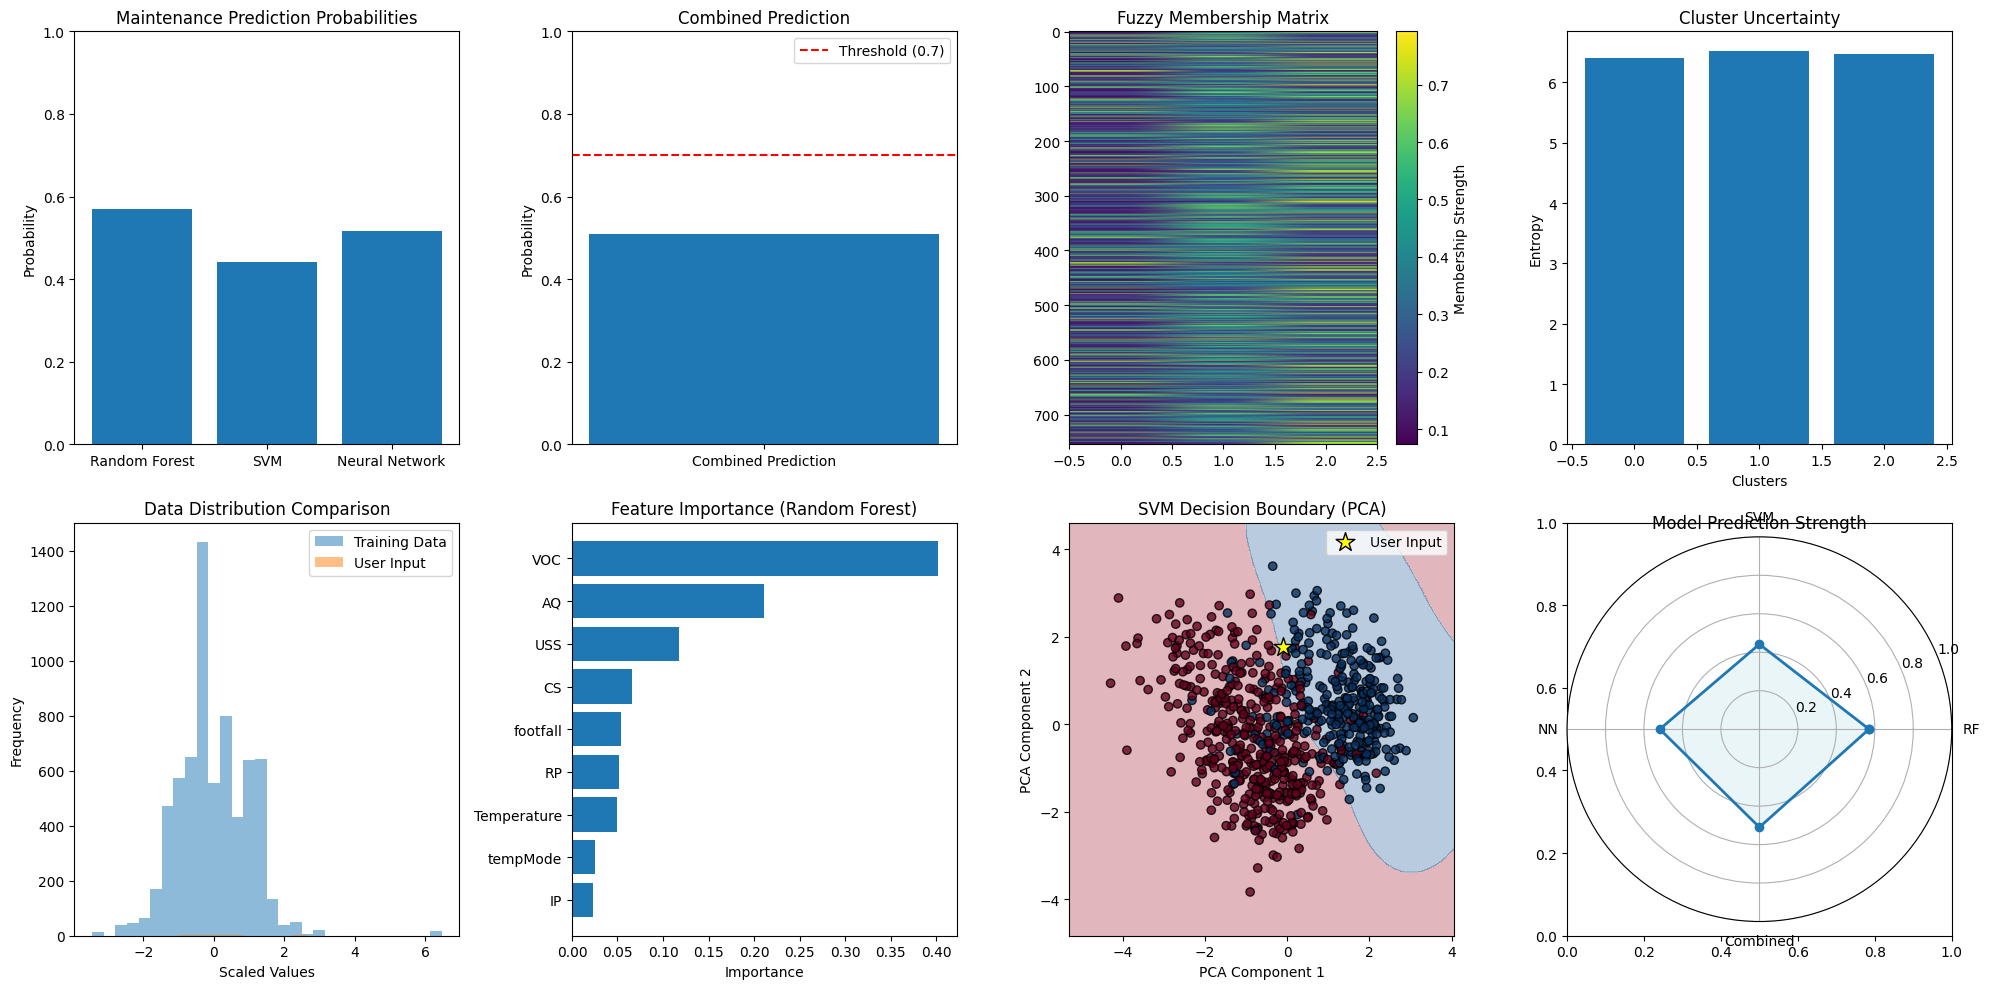

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


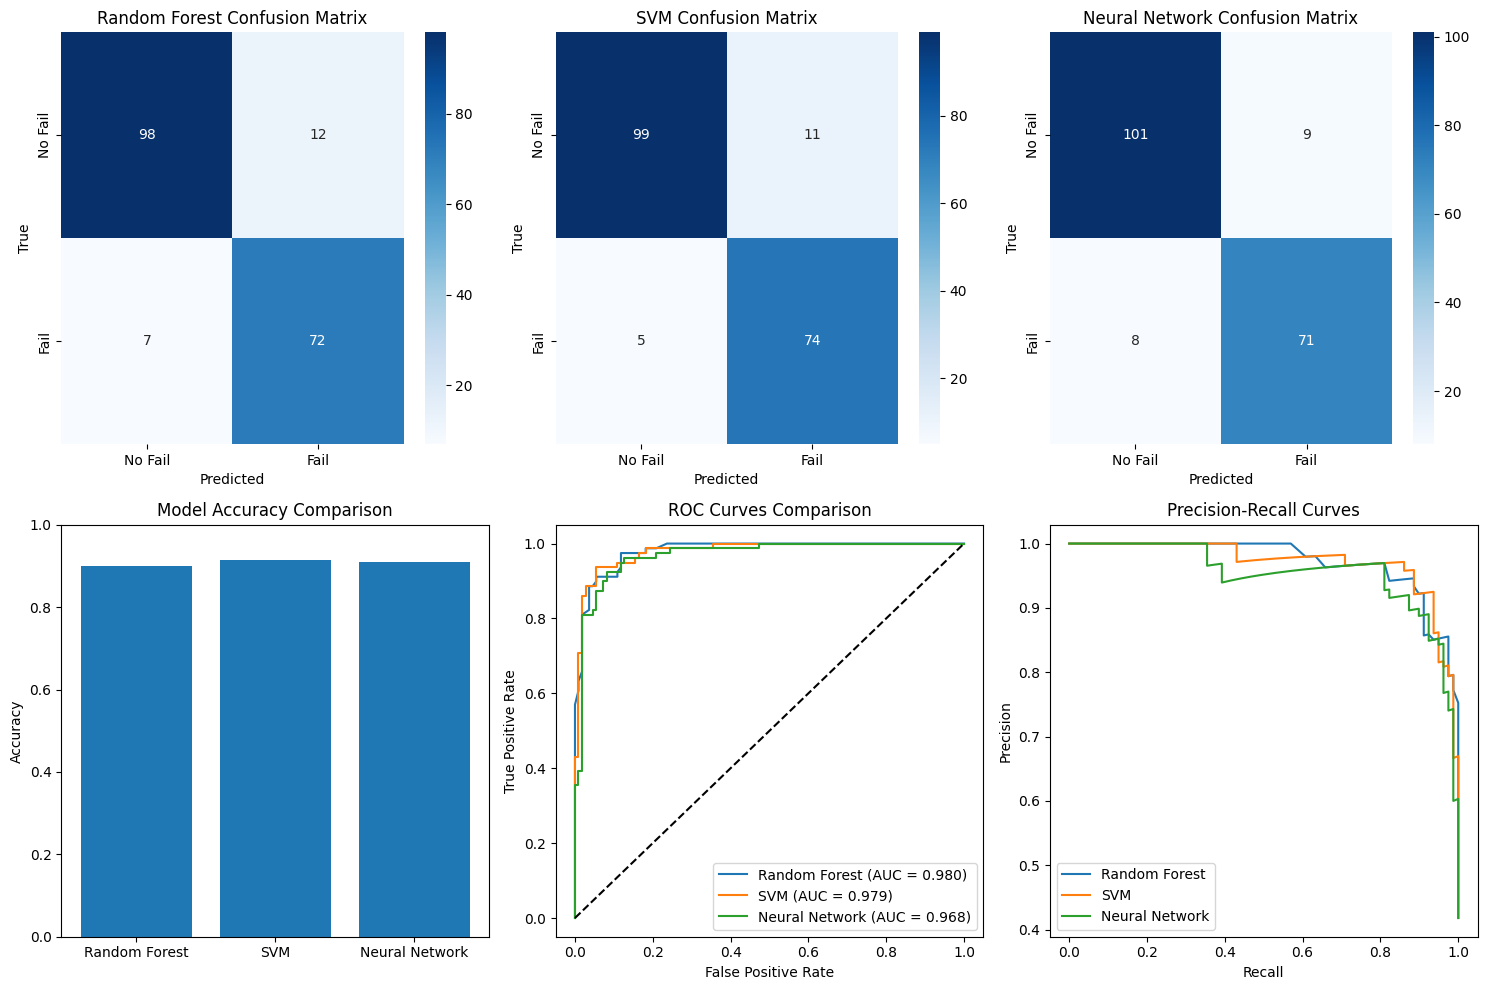


--- MODEL COMPARISON ---

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.89      0.91       110
           1       0.86      0.91      0.88        79

    accuracy                           0.90       189
   macro avg       0.90      0.90      0.90       189
weighted avg       0.90      0.90      0.90       189


SVM Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.90      0.93       110
           1       0.87      0.94      0.90        79

    accuracy                           0.92       189
   macro avg       0.91      0.92      0.91       189
weighted avg       0.92      0.92      0.92       189


Neural Network Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.92      0.92       110
           1       0.89      0.90      0.89        79

    accuracy                           0.91       1

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC  # Added SVM classifier
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Model
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.stats import entropy

class AdvancedFuzzyCMeans:
    def __init__(self,
                 n_clusters=3,
                 m=2,
                 max_iter=200,
                 error=1e-6,
                 kernel_type='gaussian',
                 regularization=1e-4):
        """
        Advanced Fuzzy C-Means Clustering with Enhanced Features
        """
        self.n_clusters = n_clusters
        self.m = m
        self.max_iter = max_iter
        self.error = error
        self.kernel_type = kernel_type
        self.regularization = regularization

        self.centers = None
        self.u = None
        self.cluster_entropies = None
        self.silhouette_scores = None

    def _kernel_function(self, X):
        """
        Apply kernel transformation for non-linear clustering
        """
        if self.kernel_type == 'gaussian':
            gamma = 1.0 / (2 * X.shape[1])
            pairwise_dists = cdist(X, X, 'euclidean')
            return np.exp(-gamma * (pairwise_dists ** 2))
        elif self.kernel_type == 'polynomial':
            return (1 + X @ X.T) ** 3
        else:
            return X

    def fit(self, X):
        """
        Perform Advanced Fuzzy C-Means Clustering
        """
        # Preprocessing
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)

        # Apply PCA for dimensionality reduction and noise reduction
        pca = PCA(n_components=min(X.shape[1], 10))
        X_pca = pca.fit_transform(X_scaled)

        # Apply kernel transformation
        X_kernel = self._kernel_function(X_pca)

        # Initialize membership matrix
        n_samples, n_features = X_kernel.shape
        self.u = np.random.dirichlet(np.ones(self.n_clusters), size=n_samples)
        self.u = self.u / self.u.sum(axis=1)[:, np.newaxis]

        # Tracking variables
        cluster_histories = []

        for iteration in range(self.max_iter):
            # Store previous centers
            old_centers = self.centers.copy() if self.centers is not None else None

            # Update cluster centers with regularization
            self.centers = self._update_centers(X_kernel)

            # Update membership matrix
            new_u = self._update_membership(X_kernel)

            # Compute cluster entropies
            self.cluster_entropies = self._compute_cluster_entropies(new_u)

            # Track cluster centers history
            cluster_histories.append(self.centers.copy())

            # Check convergence
            if old_centers is not None:
                center_change = np.linalg.norm(self.centers - old_centers)
                if center_change < self.error:
                    break

            self.u = new_u

        # Compute silhouette scores
        self.silhouette_scores = self._compute_silhouette_scores(X_kernel)

        return {
            'centers': self.centers,
            'membership_matrix': self.u,
            'cluster_entropies': self.cluster_entropies,
            'silhouette_scores': self.silhouette_scores,
            'cluster_histories': cluster_histories
        }

    def _update_centers(self, X):
        """
        Update cluster centers with regularization
        """
        um = self.u ** self.m
        numerator = um.T @ X
        denominator = um.sum(axis=0)[:, np.newaxis]

        # Add regularization to prevent singularity
        centers = numerator / (denominator + self.regularization)
        return centers

    def _update_membership(self, X):
        """
        Update membership matrix with advanced distance calculation
        """
        distances = cdist(X, self.centers)
        distances = np.maximum(distances, 1e-10)

        # Enhanced membership calculation
        membership = 1 / (distances ** (2 / (self.m - 1)) *
                          np.sum((1 / distances) ** (2 / (self.m - 1)), axis=1)[:, np.newaxis])

        return membership

    def _compute_cluster_entropies(self, membership):
        """
        Compute entropy for each cluster to measure uncertainty
        """
        return [entropy(cluster_mem) for cluster_mem in membership.T]

    def _compute_silhouette_scores(self, X):
        """
        Compute silhouette scores for cluster validation
        """
        cluster_labels = np.argmax(self.u, axis=1)
        return silhouette_score(X, cluster_labels)

    def visualize_clustering(self, X, results):
        """
        Comprehensive visualization of clustering results
        """
        plt.figure(figsize=(16, 5))

        # Cluster Centers Evolution
        plt.subplot(131)
        histories = results['cluster_histories']
        for i in range(len(histories[0])):
            center_trajectory = [h[i] for h in histories]
            plt.plot(center_trajectory, label=f'Cluster {i+1}')
        plt.title('Cluster Centers Evolution')
        plt.xlabel('Iterations')
        plt.ylabel('Center Position')
        plt.legend()

        # Membership Distribution
        plt.subplot(132)
        plt.imshow(results['membership_matrix'], aspect='auto', cmap='viridis')
        plt.title('Membership Matrix')
        plt.xlabel('Clusters')
        plt.ylabel('Samples')
        plt.colorbar(label='Membership Strength')

        # Cluster Entropies
        plt.subplot(133)
        plt.bar(range(len(results['cluster_entropies'])), results['cluster_entropies'])
        plt.title('Cluster Entropy')
        plt.xlabel('Clusters')
        plt.ylabel('Entropy')

        plt.tight_layout()
        plt.show()

class ComprehensivePredictiveMaintenance:
    def __init__(self, data_path):
        """
        Comprehensive Predictive Maintenance System with Advanced Fuzzy Clustering
        """
        self.data_path = data_path
        self.load_data()

    def load_data(self):
        """
        Load and prepare the dataset
        """
        self.df = pd.read_csv(self.data_path)

        # Separate features and target
        self.X = self.df.drop('fail', axis=1)
        self.y = self.df['fail']

    def preprocess_data(self):
        """
        Preprocess data for multiple models
        """
        # Scale features
        self.scaler = StandardScaler()
        X_scaled = self.scaler.fit_transform(self.X)

        # Split the data
        X_train, X_test, y_train, y_test = train_test_split(
            X_scaled, self.y,
            test_size=0.2,
            random_state=42,
            stratify=self.y
        )

        return X_train, X_test, y_train, y_test

    def train_models(self, X_train, y_train):
        """
        Train multiple models including SVM
        """
        # Random Forest
        rf_model = RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            class_weight='balanced'
        )
        rf_model.fit(X_train, y_train)

        # Support Vector Machine
        svm_model = SVC(
            probability=True,  # Enable probability estimates
            kernel='rbf',      # Radial basis function kernel
            C=1.0,             # Regularization parameter
            gamma='scale',     # Kernel coefficient
            class_weight='balanced',  # Handle class imbalance
            random_state=42
        )
        svm_model.fit(X_train, y_train)

        # Neural Network
        nn_model = self._create_neural_network(X_train.shape[1])
        nn_model.fit(
            X_train, y_train,
            epochs=200,
            batch_size=32,
            validation_split=0.2,
            verbose=0
        )

        return rf_model, svm_model, nn_model

    def _create_neural_network(self, input_shape):
        """
        Create Advanced Neural Network model using Input layer
        """
        # Create input layer
        inputs = Input(shape=(input_shape,))

        # Add layers
        x = Dense(128, activation='relu')(inputs)
        x = Dropout(0.4)(x)
        x = Dense(64, activation='relu')(x)
        x = Dropout(0.3)(x)
        x = Dense(32, activation='relu')(x)
        x = Dropout(0.2)(x)
        outputs = Dense(1, activation='sigmoid')(x)

        # Create model
        model = Model(inputs=inputs, outputs=outputs)

        model.compile(
            optimizer=Adam(learning_rate=0.0005),
            loss='binary_crossentropy',
            metrics=['accuracy']
        )

        return model

    def predict_maintenance(self, user_input):
        """
        Advanced Maintenance Prediction with Multiple Techniques including SVM
        """
        # Preprocess and train models
        X_train, X_test, y_train, y_test = self.preprocess_data()
        rf_model, svm_model, nn_model = self.train_models(X_train, y_train)

        # Advanced Fuzzy C-Means Clustering
        fcm = AdvancedFuzzyCMeans(
            n_clusters=3,
            m=2.0,
            max_iter=300,
            kernel_type='gaussian'
        )
        clustering_results = fcm.fit(X_train)

        # Prepare user input
        input_df = pd.DataFrame([user_input], columns=self.X.columns)
        input_df.fillna(0, inplace=True)
        input_scaled = self.scaler.transform(input_df)

        # Predictions
        rf_pred_proba = rf_model.predict_proba(input_scaled)[0, 1]
        svm_pred_proba = svm_model.predict_proba(input_scaled)[0, 1]
        nn_pred_proba = nn_model.predict(input_scaled)[0, 0]

        # Combine predictions with clustering insights
        combined_pred = (rf_pred_proba + svm_pred_proba + nn_pred_proba) / 3

        # Visualize comprehensive results
        self._visualize_comprehensive_results(
            rf_model, svm_model, nn_model, fcm,
            X_train, y_train, input_scaled,  # Fixed: passing y_train here
            clustering_results,
            rf_pred_proba, svm_pred_proba, nn_pred_proba
        )

        # Model comparison metrics on test set
        self._compare_model_performance(X_train, X_test, y_train, y_test,
                                        rf_model, svm_model, nn_model)

        return {
            'Random Forest Probability': rf_pred_proba,
            'SVM Probability': svm_pred_proba,
            'Neural Network Probability': nn_pred_proba,
            'Combined Maintenance Probability': combined_pred,
            'Maintenance Needed': combined_pred > 0.7,
            'Cluster Entropies': clustering_results['cluster_entropies'],
            'Silhouette Score': clustering_results['silhouette_scores']
        }

    def _compare_model_performance(self, X_train, X_test, y_train, y_test,
                                  rf_model, svm_model, nn_model):
        """
        Compare performance of different models
        """
        # Make predictions
        rf_preds = rf_model.predict(X_test)
        svm_preds = svm_model.predict(X_test)
        nn_preds = (nn_model.predict(X_test) > 0.5).astype(int).flatten()

        # Calculate metrics
        models = ['Random Forest', 'SVM', 'Neural Network']
        predictions = [rf_preds, svm_preds, nn_preds]

        # Display comparisons
        plt.figure(figsize=(15, 10))

        # 1. Confusion Matrices
        for i, (model, preds) in enumerate(zip(models, predictions)):
            plt.subplot(2, 3, i+1)
            cm = confusion_matrix(y_test, preds)
            sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                        xticklabels=['No Fail', 'Fail'],
                        yticklabels=['No Fail', 'Fail'])
            plt.title(f'{model} Confusion Matrix')
            plt.ylabel('True')
            plt.xlabel('Predicted')

        # 2. Model Accuracy Comparison
        plt.subplot(2, 3, 4)
        accuracies = [(preds == y_test).mean() for preds in predictions]
        plt.bar(models, accuracies)
        plt.title('Model Accuracy Comparison')
        plt.ylabel('Accuracy')
        plt.ylim(0, 1)

        # 3. ROC Curves
        plt.subplot(2, 3, 5)
        from sklearn.metrics import roc_curve, auc

        # Get probabilities
        rf_proba = rf_model.predict_proba(X_test)[:, 1]
        svm_proba = svm_model.predict_proba(X_test)[:, 1]
        nn_proba = nn_model.predict(X_test).flatten()

        # Calculate ROC curves
        for model_name, y_pred in zip(models, [rf_proba, svm_proba, nn_proba]):
            fpr, tpr, _ = roc_curve(y_test, y_pred)
            auc_score = auc(fpr, tpr)
            plt.plot(fpr, tpr, label=f'{model_name} (AUC = {auc_score:.3f})')

        plt.plot([0, 1], [0, 1], 'k--')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title('ROC Curves Comparison')
        plt.legend()

        # 4. Precision-Recall
        plt.subplot(2, 3, 6)
        from sklearn.metrics import precision_recall_curve

        for model_name, y_pred in zip(models, [rf_proba, svm_proba, nn_proba]):
            precision, recall, _ = precision_recall_curve(y_test, y_pred)
            plt.plot(recall, precision, label=model_name)

        plt.xlabel('Recall')
        plt.ylabel('Precision')
        plt.title('Precision-Recall Curves')
        plt.legend()

        plt.tight_layout()
        plt.show()

        # Print classification reports
        print("\n--- MODEL COMPARISON ---")
        for i, (model, preds) in enumerate(zip(models, predictions)):
            print(f"\n{model} Classification Report:")
            print(classification_report(y_test, preds))

    def _visualize_comprehensive_results(
        self, rf_model, svm_model, nn_model, fcm,
        X_train, y_train, input_data,  # Fixed: added y_train parameter
        clustering_results,
        rf_pred, svm_pred, nn_pred
    ):
        """
        Comprehensive Visualization of Prediction and Clustering Results
        """
        plt.figure(figsize=(20, 10))

        # Prediction Probabilities
        plt.subplot(241)
        predictions = [rf_pred, svm_pred, nn_pred]
        models = ['Random Forest', 'SVM', 'Neural Network']
        plt.bar(models, predictions)
        plt.title('Maintenance Prediction Probabilities')
        plt.ylabel('Probability')
        plt.ylim(0, 1)

        # Combined Prediction
        plt.subplot(242)
        combined = np.mean(predictions)
        plt.bar(['Combined Prediction'], [combined])
        plt.axhline(y=0.7, color='r', linestyle='--', label='Threshold (0.7)')
        plt.title('Combined Prediction')
        plt.ylabel('Probability')
        plt.ylim(0, 1)
        plt.legend()

        # Fuzzy Clustering Visualization
        plt.subplot(243)
        membership_matrix = clustering_results['membership_matrix']
        plt.imshow(membership_matrix, aspect='auto', cmap='viridis')
        plt.title('Fuzzy Membership Matrix')
        plt.colorbar(label='Membership Strength')

        # Cluster Entropies
        plt.subplot(244)
        plt.bar(
            range(len(clustering_results['cluster_entropies'])),
            clustering_results['cluster_entropies']
        )
        plt.title('Cluster Uncertainty')
        plt.xlabel('Clusters')
        plt.ylabel('Entropy')

        # Input vs Training Data Distribution
        plt.subplot(245)
        plt.hist(X_train.flatten(), bins=30, alpha=0.5, label='Training Data')
        plt.hist(input_data.flatten(), bins=10, alpha=0.5, label='User Input')
        plt.title('Data Distribution Comparison')
        plt.xlabel('Scaled Values')
        plt.ylabel('Frequency')
        plt.legend()

        # Feature Importance (Random Forest)
        plt.subplot(246)
        feature_importances = rf_model.feature_importances_
        feature_names = self.X.columns
        sorted_idx = np.argsort(feature_importances)
        plt.barh(range(len(sorted_idx)), feature_importances[sorted_idx])
        plt.yticks(range(len(sorted_idx)), [feature_names[i] for i in sorted_idx])
        plt.title('Feature Importance (Random Forest)')
        plt.xlabel('Importance')

        # SVM Decision Boundary Visualization (2D PCA projection)
        plt.subplot(247)

        # Create a 2D PCA projection for visualization
        pca = PCA(n_components=2)
        X_train_pca = pca.fit_transform(X_train)
        input_pca = pca.transform(input_data)

        # Create a mesh grid for visualization
        h = 0.02  # Step size
        x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
        y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
        xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                             np.arange(y_min, y_max, h))

        # Fit SVM on the 2D PCA projection for visualization
        svm_2d = SVC(probability=True, kernel='rbf', gamma='scale')
        svm_2d.fit(X_train_pca, y_train)  # Now y_train is available

        # Plot decision boundary
        Z = svm_2d.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.RdBu)

        # Plot training points
        plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train,
                   cmap=plt.cm.RdBu, alpha=0.8, edgecolors='k')

        # Highlight input point
        plt.scatter(input_pca[:, 0], input_pca[:, 1], marker='*', s=200,
                   c='yellow', edgecolors='k', label='User Input')

        plt.title('SVM Decision Boundary (PCA)')
        plt.xlabel('PCA Component 1')
        plt.ylabel('PCA Component 2')
        plt.legend()

        # Model comparison in terms of prediction strength
        plt.subplot(248)
        models = ['RF', 'SVM', 'NN', 'Combined']
        predictions = [rf_pred, svm_pred, nn_pred, combined]
        colors = ['blue', 'green', 'orange', 'red']

        # Create radar chart for model comparison
        angles = np.linspace(0, 2*np.pi, len(models), endpoint=False).tolist()
        angles += angles[:1]  # Close the loop

        ax = plt.subplot(248, polar=True)
        values = predictions + predictions[:1]  # Close the loop
        ax.fill(angles, values, color='lightblue', alpha=0.25)
        ax.plot(angles, values, 'o-', linewidth=2)
        ax.set_thetagrids(np.degrees(angles[:-1]), models)
        ax.set_ylim(0, 1)
        ax.set_title('Model Prediction Strength')

        plt.tight_layout()
        plt.show()

def run_maintenance_prediction(data_path):
    """
    Simplified Maintenance Prediction Interface
    """
    # Initialize the system
    predictor = ComprehensivePredictiveMaintenance(data_path)

    # Direct input for feature values
    print("\n--- Predictive Maintenance System ---")
    print("Enter sensor measurements:")

    user_input = {
        'footfall': float(input("Enter footfall value (min(1),max(7300)): ")),
        'tempMode': float(input("Enter tempMode value (min(0),max(7)): ")),
        'AQ': float(input("Enter AQ value (min(0),max(7)): ")),
        'USS': float(input("Enter USS value (min(0),max(7)): ")),
        'CS': float(input("Enter CS value (min(0),max(7)): ")),
        'VOC': float(input("Enter VOC value (min(0),max(6)): ")),
        'RP': float(input("Enter RP value (min(19),max(91)): ")),
        'IP': float(input("Enter IP value (min(1),max(7)): ")),
        'Temperature': float(input("Enter Temperature value (min(1)),max(24)): "))
    }

    # Predict maintenance
    result = predictor.predict_maintenance(user_input)

    # Print results
    print("\n--- Maintenance Prediction Results ---")
    for key, value in result.items():
        print(f"{key}: {value}")

# Usage Example
if __name__ == '__main__':
    # Replace with your actual data path
    DATA_PATH = '/content/Sensor Data.csv'

    # Run simplified prediction
    run_maintenance_prediction(DATA_PATH)

###Summary of Evolution

####Implementation - Key Contribution

1. **Basic RF** - Baseline model with essential metrics
2. **SMOTE + GridSearch**	- Handles imbalance & optimizes hyperparameters
3. **Enhanced EDA** - Adds anomaly detection & feature analysis
4. **Multiclass** - Extends to multiple failure types
5. **NN Comparison** - Introduces Neural Networks
6. **Fuzzy C-Means** - Adds unsupervised clustering
7. **Advanced FCM** -	Kernel methods & entropy analysis
8. **SVM Integration** - Compares RF, SVM, and NN

####Digital Assignment - I

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Model
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.stats import entropy

class AdvancedFuzzyCMeans:
    def __init__(self,
                 n_clusters=3,
                 m=2,
                 max_iter=200,
                 error=1e-6,
                 kernel_type='gaussian',
                 regularization=1e-4):
        """
        Advanced Fuzzy C-Means Clustering with Enhanced Features
        """
        self.n_clusters = n_clusters
        self.m = m
        self.max_iter = max_iter
        self.error = error
        self.kernel_type = kernel_type
        self.regularization = regularization

        self.centers = None
        self.u = None
        self.cluster_entropies = None
        self.silhouette_scores = None

    def _kernel_function(self, X):
        """
        Apply kernel transformation for non-linear clustering
        """
        if self.kernel_type == 'gaussian':
            gamma = 1.0 / (2 * X.shape[1])
            pairwise_dists = cdist(X, X, 'euclidean')
            return np.exp(-gamma * (pairwise_dists ** 2))
        elif self.kernel_type == 'polynomial':
            return (1 + X @ X.T) ** 3
        else:
            return X

    def fit(self, X):
        """
        Perform Advanced Fuzzy C-Means Clustering
        """
        # Preprocessing
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)

        # Apply PCA for dimensionality reduction and noise reduction
        pca = PCA(n_components=min(X.shape[1], 10))
        X_pca = pca.fit_transform(X_scaled)

        # Apply kernel transformation
        X_kernel = self._kernel_function(X_pca)

        # Initialize membership matrix
        n_samples, n_features = X_kernel.shape
        self.u = np.random.dirichlet(np.ones(self.n_clusters), size=n_samples)
        self.u = self.u / self.u.sum(axis=1)[:, np.newaxis]

        # Tracking variables
        cluster_histories = []

        for iteration in range(self.max_iter):
            # Store previous centers
            old_centers = self.centers.copy() if self.centers is not None else None

            # Update cluster centers with regularization
            self.centers = self._update_centers(X_kernel)

            # Update membership matrix
            new_u = self._update_membership(X_kernel)

            # Compute cluster entropies
            self.cluster_entropies = self._compute_cluster_entropies(new_u)

            # Track cluster centers history
            cluster_histories.append(self.centers.copy())

            # Check convergence
            if old_centers is not None:
                center_change = np.linalg.norm(self.centers - old_centers)
                if center_change < self.error:
                    break

            self.u = new_u

        # Compute silhouette scores
        self.silhouette_scores = self._compute_silhouette_scores(X_kernel)

        return {
            'centers': self.centers,
            'membership_matrix': self.u,
            'cluster_entropies': self.cluster_entropies,
            'silhouette_scores': self.silhouette_scores,
            'cluster_histories': cluster_histories
        }

    def _update_centers(self, X):
        """
        Update cluster centers with regularization
        """
        um = self.u ** self.m
        numerator = um.T @ X
        denominator = um.sum(axis=0)[:, np.newaxis]

        # Add regularization to prevent singularity
        centers = numerator / (denominator + self.regularization)
        return centers

    def _update_membership(self, X):
        """
        Update membership matrix with advanced distance calculation
        """
        distances = cdist(X, self.centers)
        distances = np.maximum(distances, 1e-10)

        # Enhanced membership calculation
        membership = 1 / (distances ** (2 / (self.m - 1)) *
                          np.sum((1 / distances) ** (2 / (self.m - 1)), axis=1)[:, np.newaxis])

        return membership

    def _compute_cluster_entropies(self, membership):
        """
        Compute entropy for each cluster to measure uncertainty
        """
        return [entropy(cluster_mem) for cluster_mem in membership.T]

    def _compute_silhouette_scores(self, X):
        """
        Compute silhouette scores for cluster validation
        """
        cluster_labels = np.argmax(self.u, axis=1)
        return silhouette_score(X, cluster_labels)

    def visualize_clustering(self, X, results):
        """
        Comprehensive visualization of clustering results
        """
        plt.figure(figsize=(16, 5))

        # Cluster Centers Evolution
        plt.subplot(131)
        histories = results['cluster_histories']
        for i in range(len(histories[0])):
            center_trajectory = [h[i] for h in histories]
            plt.plot(center_trajectory, label=f'Cluster {i+1}')
        plt.title('Cluster Centers Evolution')
        plt.xlabel('Iterations')
        plt.ylabel('Center Position')
        plt.legend()

        # Membership Distribution
        plt.subplot(132)
        plt.imshow(results['membership_matrix'], aspect='auto', cmap='viridis')
        plt.title('Membership Matrix')
        plt.xlabel('Clusters')
        plt.ylabel('Samples')
        plt.colorbar(label='Membership Strength')

        # Cluster Entropies
        plt.subplot(133)
        plt.bar(range(len(results['cluster_entropies'])), results['cluster_entropies'])
        plt.title('Cluster Entropy')
        plt.xlabel('Clusters')
        plt.ylabel('Entropy')

        plt.tight_layout()
        plt.show()

class ComprehensivePredictiveMaintenance:
    def __init__(self, data_path):
        """
        Comprehensive Predictive Maintenance System with Advanced Fuzzy Clustering
        """
        self.data_path = data_path
        self.load_data()

    def load_data(self):
        """
        Load and prepare the dataset
        """
        self.df = pd.read_csv(self.data_path)

        # Separate features and target
        self.X = self.df.drop('fail', axis=1)
        self.y = self.df['fail']

    def preprocess_data(self):
        """
        Preprocess data for multiple models
        """
        # Scale features
        self.scaler = StandardScaler()
        X_scaled = self.scaler.fit_transform(self.X)

        # Split the data
        X_train, X_test, y_train, y_test = train_test_split(
            X_scaled, self.y,
            test_size=0.2,
            random_state=42,
            stratify=self.y
        )

        return X_train, X_test, y_train, y_test

    def train_models(self, X_train, y_train):
        """
        Train multiple models
        """
        # Random Forest
        rf_model = RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            class_weight='balanced'
        )
        rf_model.fit(X_train, y_train)

        # Neural Network
        nn_model = self._create_neural_network(X_train.shape[1])
        nn_model.fit(
            X_train, y_train,
            epochs=200,  # Increased epochs
            batch_size=32,
            validation_split=0.2,
            verbose=0
        )

        return rf_model, nn_model

    def _create_neural_network(self, input_shape):
        """
        Create Advanced Neural Network model using Input layer
        """
        # Create input layer
        inputs = Input(shape=(input_shape,))

        # Add layers
        x = Dense(128, activation='relu')(inputs)
        x = Dropout(0.4)(x)
        x = Dense(64, activation='relu')(x)
        x = Dropout(0.3)(x)
        x = Dense(32, activation='relu')(x)
        x = Dropout(0.2)(x)
        outputs = Dense(1, activation='sigmoid')(x)

        # Create model
        model = Model(inputs=inputs, outputs=outputs)

        model.compile(
            optimizer=Adam(learning_rate=0.0005),
            loss='binary_crossentropy',
            metrics=['accuracy']
        )

        return model

    def predict_maintenance(self, user_input):
        """
        Advanced Maintenance Prediction with Multiple Techniques
        """
        # Preprocess and train models
        X_train, X_test, y_train, y_test = self.preprocess_data()
        rf_model, nn_model = self.train_models(X_train, y_train)

        # Advanced Fuzzy C-Means Clustering
        fcm = AdvancedFuzzyCMeans(
            n_clusters=3,
            m=2.0,
            max_iter=300,
            kernel_type='gaussian'
        )
        clustering_results = fcm.fit(X_train)

        # Prepare user input
        input_df = pd.DataFrame([user_input], columns=self.X.columns)
        input_df.fillna(0, inplace=True)
        input_scaled = self.scaler.transform(input_df)

        # Predictions
        rf_pred_proba = rf_model.predict_proba(input_scaled)[0, 1]
        nn_pred_proba = nn_model.predict(input_scaled)[0, 0]

        # Combine predictions with clustering insights
        combined_pred = (rf_pred_proba + nn_pred_proba) / 2

        # Visualize comprehensive results
        self._visualize_comprehensive_results(
            rf_model, nn_model, fcm,
            X_train, input_scaled,
            clustering_results,
            rf_pred_proba, nn_pred_proba
        )

        return {
            'Random Forest Probability': rf_pred_proba,
            'Neural Network Probability': nn_pred_proba,
            'Combined Maintenance Probability': combined_pred,
            'Maintenance Needed': combined_pred > 0.7,
            'Cluster Entropies': clustering_results['cluster_entropies'],
            'Silhouette Score': clustering_results['silhouette_scores']
        }

    def _visualize_comprehensive_results(
        self, rf_model, nn_model, fcm,
        X_train, input_data,
        clustering_results,
        rf_pred, nn_pred
    ):
        """
        Comprehensive Visualization of Prediction and Clustering Results
        """
        plt.figure(figsize=(20, 5))

        # Prediction Probabilities
        plt.subplot(141)
        predictions = [rf_pred, nn_pred]
        models = ['Random Forest', 'Neural Network']
        plt.bar(models, predictions)
        plt.title('Maintenance Prediction Probabilities')
        plt.ylabel('Probability')
        plt.ylim(0, 1)

        # Fuzzy Clustering Visualization
        plt.subplot(142)
        membership_matrix = clustering_results['membership_matrix']
        plt.imshow(membership_matrix, aspect='auto', cmap='viridis')
        plt.title('Fuzzy Membership Matrix')
        plt.colorbar(label='Membership Strength')

        # Cluster Entropies
        plt.subplot(143)
        plt.bar(
            range(len(clustering_results['cluster_entropies'])),
            clustering_results['cluster_entropies']
        )
        plt.title('Cluster Uncertainty')
        plt.xlabel('Clusters')
        plt.ylabel('Entropy')

        # Input vs Training Data Distribution
        plt.subplot(144)
        plt.hist(X_train.flatten(), bins=30, alpha=0.5, label='Training Data')
        plt.hist(input_data.flatten(), bins=10, alpha=0.5, label='User Input')
        plt.title('Data Distribution Comparison')
        plt.xlabel('Scaled Values')
        plt.ylabel('Frequency')
        plt.legend()

        plt.tight_layout()
        plt.show()

def print_architecture():
    """
    Prints the architecture of the predictive maintenance system
    """
    print("\n=== PREDICTIVE MAINTENANCE SYSTEM ARCHITECTURE ===\n")

    # Print AdvancedFuzzyCMeans architecture
    print("1. ADVANCED FUZZY C-MEANS CLUSTERING")
    print("   - Initialization parameters: n_clusters, m (fuzziness), max_iter, error threshold")
    print("   - Kernel transformations: gaussian, polynomial")
    print("   - PCA for dimensionality reduction")
    print("   - Regularized center updates")
    print("   - Entropy-based uncertainty measurement")
    print("   - Silhouette score calculation")
    print()

    # Print Neural Network architecture
    print("2. NEURAL NETWORK MODEL")
    print("   - Input Layer: Shape based on feature count")
    print("   - Hidden Layer 1: Dense(128, relu) → Dropout(0.4)")
    print("   - Hidden Layer 2: Dense(64, relu) → Dropout(0.3)")
    print("   - Hidden Layer 3: Dense(32, relu) → Dropout(0.2)")
    print("   - Output Layer: Dense(1, sigmoid)")
    print("   - Optimizer: Adam(lr=0.0005)")
    print("   - Loss: Binary Cross-Entropy")
    print()

    # Print Random Forest architecture
    print("3. RANDOM FOREST CLASSIFIER")
    print("   - n_estimators: 100")
    print("   - class_weight: balanced")
    print()

    # Print Ensemble approach
    print("4. ENSEMBLE METHODOLOGY")
    print("   - Combined prediction from RF and NN models")
    print("   - Integration with clustering insights")
    print("   - Maintenance threshold: probability > 0.7")
    print()

    # Print Data Pipeline
    print("5. DATA PROCESSING PIPELINE")
    print("   - StandardScaler for feature normalization")
    print("   - Stratified train-test splitting (80% train, 20% test)")
    print("   - Input validation and preprocessing")
    print()

    # Print Visualization capabilities
    print("6. VISUALIZATION COMPONENTS")
    print("   - Prediction probabilities comparison")
    print("   - Fuzzy membership matrix visualization")
    print("   - Cluster entropy analysis")
    print("   - Input vs. training data distribution")
    print()

    print("=== END OF ARCHITECTURE DESCRIPTION ===")

def print_nn_architecture(input_shape=9):
    """
    Creates and prints the neural network architecture
    """
    # Create the neural network
    inputs = Input(shape=(input_shape,))
    x = Dense(128, activation='relu')(inputs)
    x = Dropout(0.4)(x)
    x = Dense(64, activation='relu')(x)
    x = Dropout(0.3)(x)
    x = Dense(32, activation='relu')(x)
    x = Dropout(0.2)(x)
    outputs = Dense(1, activation='sigmoid')(x)

    model = Model(inputs=inputs, outputs=outputs)
    model.compile(
        optimizer=Adam(learning_rate=0.0005),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    # Print the model summary
    print("\n=== NEURAL NETWORK ARCHITECTURE ===\n")
    model.summary()
    print("\n=== END OF NEURAL NETWORK ARCHITECTURE ===\n")

    return model

def run_maintenance_prediction(data_path):
    """
    Simplified Maintenance Prediction Interface
    """
    # Initialize the system
    predictor = ComprehensivePredictiveMaintenance(data_path)

    # Direct input for feature values
    print("\n--- Predictive Maintenance System ---")
    print("Enter sensor measurements:")

    user_input = {
        'footfall': float(input("Enter footfall value (min(1),max(7300)): ")),
        'tempMode': float(input("Enter tempMode value (min(0),max(7)): ")),
        'AQ': float(input("Enter AQ value (min(0),max(7)): ")),
        'USS': float(input("Enter USS value (min(0),max(7)): ")),
        'CS': float(input("Enter CS value (min(0),max(7)): ")),
        'VOC': float(input("Enter VOC value (min(0),max(6)): ")),
        'RP': float(input("Enter RP value (min(19),max(91)): ")),
        'IP': float(input("Enter IP value (min(1),max(7)): ")),
        'Temperature': float(input("Enter Temperature value (min(1)),max(24)): "))
    }

    # Predict maintenance
    result = predictor.predict_maintenance(user_input)

    # Print results
    print("\n--- Maintenance Prediction Results ---")
    for key, value in result.items():
        print(f"{key}: {value}")

# Usage Example
if __name__ == '__main__':
    # Replace with your actual data path
    DATA_PATH = '/content/Sensor Data.csv'

    # Print architecture
    print_architecture()

    # Print neural network architecture with model summary
    print_nn_architecture()

    # Run simplified prediction
    run_maintenance_prediction(DATA_PATH)


=== PREDICTIVE MAINTENANCE SYSTEM ARCHITECTURE ===

1. ADVANCED FUZZY C-MEANS CLUSTERING
   - Initialization parameters: n_clusters, m (fuzziness), max_iter, error threshold
   - Kernel transformations: gaussian, polynomial
   - PCA for dimensionality reduction
   - Regularized center updates
   - Entropy-based uncertainty measurement
   - Silhouette score calculation

2. NEURAL NETWORK MODEL
   - Input Layer: Shape based on feature count
   - Hidden Layer 1: Dense(128, relu) → Dropout(0.4)
   - Hidden Layer 2: Dense(64, relu) → Dropout(0.3)
   - Hidden Layer 3: Dense(32, relu) → Dropout(0.2)
   - Output Layer: Dense(1, sigmoid)
   - Optimizer: Adam(lr=0.0005)
   - Loss: Binary Cross-Entropy

3. RANDOM FOREST CLASSIFIER
   - n_estimators: 100
   - class_weight: balanced

4. ENSEMBLE METHODOLOGY
   - Combined prediction from RF and NN models
   - Integration with clustering insights
   - Maintenance threshold: probability > 0.7

5. DATA PROCESSING PIPELINE
   - StandardScaler for featu

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 9)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,649 (45.50 KB)

 Trainable params: 11,649 (45.50 KB)

 Non-trainable params: 0 (0.00 B)


=== END OF NEURAL NETWORK ARCHITECTURE ===


--- Predictive Maintenance System ---
Enter sensor measurements:
